In [1]:
import pandas as pd
import numpy as np

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 3.0.3
NumPy: 2.4.6


In [2]:
import pandas as pd

file_path = "../data/raw/Amazon_Sale_Report.csv"

df = pd.read_csv(file_path)

print("Dataset successfully loaded!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

C:\Users\Josipa\AppData\Local\Temp\ipykernel_13784\2373676675.py:5: DtypeWarning: Columns (0: Unnamed: 22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


Dataset successfully loaded!
Rows: 128975
Columns: 24


In [3]:
print("=== COLUMN NAMES ===")
print(df.columns.tolist())

print("\n=== DATA TYPES ===")
print(df.dtypes)

print("\n=== FIRST 5 ROWS ===")
display(df.head())

=== COLUMN NAMES ===
['index', 'Order ID', 'Date', 'Status', 'Fulfilment', 'Sales Channel ', 'ship-service-level', 'Style', 'SKU', 'Category', 'Size', 'ASIN', 'Courier Status', 'Qty', 'currency', 'Amount', 'ship-city', 'ship-state', 'ship-postal-code', 'ship-country', 'promotion-ids', 'B2B', 'fulfilled-by', 'Unnamed: 22']

=== DATA TYPES ===
index                   int64
Order ID                  str
Date                      str
Status                    str
Fulfilment                str
Sales Channel             str
ship-service-level        str
Style                     str
SKU                       str
Category                  str
Size                      str
ASIN                      str
Courier Status            str
Qty                     int64
currency                  str
Amount                float64
ship-city                 str
ship-state                str
ship-postal-code      float64
ship-country              str
promotion-ids             str
B2B                      b

,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN


In [4]:
print("=== DATASET INFO ===")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

print("\n=== MISSING VALUES ===")
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)

missing_report = pd.DataFrame({
    "Missing Values": missing,
    "Missing %": missing_pct.round(2)
})

display(missing_report)

print("\n=== DUPLICATE ROWS ===")
print("Duplicate rows:", df.duplicated().sum())

print("\n=== UNIQUE VALUES ===")
print(df.nunique().sort_values(ascending=False))

=== DATASET INFO ===
Rows: 128,975
Columns: 24

=== MISSING VALUES ===


,Missing Values,Missing %
fulfilled-by,89698,69.55
promotion-ids,49153,38.11
Unnamed: 22,49050,38.03
currency,7795,6.04
Amount,7795,6.04
Courier Status,6872,5.33
ship-country,33,0.03
ship-city,33,0.03
ship-state,33,0.03
ship-postal-code,33,0.03



=== DUPLICATE ROWS ===
Duplicate rows: 0

=== UNIQUE VALUES ===
index                 128975
Order ID              120378
ship-postal-code        9459
ship-city               8955
SKU                     7195
ASIN                    7190
promotion-ids           5787
Amount                  1410
Style                   1377
Date                      91
ship-state                69
Status                    13
Size                      11
Qty                       10
Category                   9
Courier Status             3
ship-service-level         2
Sales Channel              2
Fulfilment                 2
B2B                        2
currency                   1
ship-country               1
fulfilled-by               1
Unnamed: 22                1
dtype: int64


In [5]:
print("=== FULFILMENT vs FULFILLED-BY ===")

display(
    pd.crosstab(
        df["Fulfilment"],
        df["fulfilled-by"],
        dropna=False
    )
)

print("\n=== STATUS vs AMOUNT MISSING ===")

amount_missing = df["Amount"].isna()

display(
    pd.crosstab(
        df["Status"],
        amount_missing,
        margins=True
    )
)

print("\n=== ORDER ID FREQUENCY ===")

order_frequency = df["Order ID"].value_counts()

display(order_frequency.describe())

print("\nOrders appearing more than once:",
      (order_frequency > 1).sum())

=== FULFILMENT vs FULFILLED-BY ===


fulfilled-by,Easy Ship,NaN
Fulfilment,,
Amazon,0,89698
Merchant,39277,0



=== STATUS vs AMOUNT MISSING ===


Amount,False,True,All
Status,,,
Cancelled,10766,7566,18332
Pending,656,2,658
Pending - Waiting for Pick Up,281,0,281
Shipped,77596,208,77804
Shipped - Damaged,1,0,1
Shipped - Delivered to Buyer,28761,8,28769
Shipped - Lost in Transit,5,0,5
Shipped - Out for Delivery,35,0,35
Shipped - Picked Up,973,0,973



=== ORDER ID FREQUENCY ===


count    120378.000000
mean          1.071417
std           0.335888
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          12.000000
Name: count, dtype: float64


Orders appearing more than once: 6846


In [6]:
print("=== UNNAMED: 22 ===")

print("Unique values:")
print(df["Unnamed: 22"].unique())

print("\nValue counts:")
display(df["Unnamed: 22"].value_counts(dropna=False))

print("\nNon-null examples:")
display(
    df[df["Unnamed: 22"].notna()][
        ["Order ID", "Status", "Amount", "Unnamed: 22"]
    ].head(20)
)

=== UNNAMED: 22 ===
Unique values:
[nan False]

Value counts:


Unnamed: 22
False    79925
NaN      49050
Name: count, dtype: int64


Non-null examples:


,Order ID,Status,Amount,Unnamed: 22
49050,403-5326073-3735562,Shipped,345.00,False
49051,408-4858463-2356347,Shipped - Delivered to Buyer,888.00,False
49052,402-4624872-7642747,Cancelled,NaN,False
49053,402-5892689-9803563,Shipped,518.00,False
49054,408-7992960-7468306,Cancelled,772.38,False
49055,408-1575008-5742745,Shipped,1199.00,False
49056,408-7491199-9117934,Shipped,423.00,False
49057,403-9533619-4173139,Shipped,371.00,False
49058,404-6751446-8259559,Shipped,899.00,False
49059,171-5611411-1357104,Shipped,967.00,False


In [7]:
print("=== PROMOTION IDS ===")

print("Unique values:", df["promotion-ids"].nunique(dropna=True))

print("\nMissing values:")
print(df["promotion-ids"].isna().sum())

print("\nValue counts - top 20:")
display(
    df["promotion-ids"]
    .value_counts(dropna=False)
    .head(20)
)

print("\nExamples with promotion:")
display(
    df[df["promotion-ids"].notna()][
        ["Order ID", "Status", "Amount", "promotion-ids"]
    ].head(20)
)

=== PROMOTION IDS ===
Unique values: 5787

Missing values:
49153

Value counts - top 20:


promotion-ids
NaN                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       


Examples with promotion:


,Order ID,Status,Amount,promotion-ids
1,171-9198151-1101146,Shipped - Delivered to Buyer,406.0,Amazon PLCC Free-Financing Universal Merchant ...
2,404-0687676-7273146,Shipped,329.0,IN Core Free Shipping 2015/04/08 23-48-5-108
5,404-1490984-4578765,Shipped,824.0,IN Core Free Shipping 2015/04/08 23-48-5-108
6,408-5748499-6859555,Shipped,653.0,IN Core Free Shipping 2015/04/08 23-48-5-108
7,406-7807733-3785945,Shipped - Delivered to Buyer,399.0,Amazon PLCC Free-Financing Universal Merchant ...
8,407-5443024-5233168,Cancelled,NaN,IN Core Free Shipping 2015/04/08 23-48-5-108
12,405-5513694-8146768,Shipped - Delivered to Buyer,399.0,Amazon PLCC Free-Financing Universal Merchant ...
14,408-1298370-1920302,Shipped - Delivered to Buyer,771.0,Amazon PLCC Free-Financing Universal Merchant ...
15,403-4965581-9520319,Shipped - Delivered to Buyer,544.0,Amazon PLCC Free-Financing Universal Merchant ...
16,406-9379318-6555504,Shipped,329.0,IN Core Free Shipping 2015/04/08 23-48-5-108


In [8]:
print("=== ORDER STATUS ===")

status_counts = (
    df["Status"]
    .value_counts(dropna=False)
    .rename_axis("Status")
    .reset_index(name="Orders")
)

status_counts["Percentage"] = (
    status_counts["Orders"] / len(df) * 100
).round(2)

display(status_counts)

=== ORDER STATUS ===


,Status,Orders,Percentage
0,Shipped,77804,60.32
1,Shipped - Delivered to Buyer,28769,22.31
2,Cancelled,18332,14.21
3,Shipped - Returned to Seller,1953,1.51
4,Shipped - Picked Up,973,0.75
5,Pending,658,0.51
6,Pending - Waiting for Pick Up,281,0.22
7,Shipped - Returning to Seller,145,0.11
8,Shipped - Out for Delivery,35,0.03
9,Shipped - Rejected by Buyer,11,0.01


In [9]:
print("=== STATUS vs QTY & AMOUNT ===")

status_analysis = (
    df.groupby("Status")
      .agg(
          Rows=("Order ID", "size"),
          Total_Qty=("Qty", "sum"),
          Amount_NonNull=("Amount", "count"),
          Total_Amount=("Amount", "sum"),
          Avg_Amount=("Amount", "mean")
      )
      .sort_values("Rows", ascending=False)
)

display(status_analysis)

=== STATUS vs QTY & AMOUNT ===


,Rows,Total_Qty,Amount_NonNull,Total_Amount,Avg_Amount
Status,,,,,
Shipped,77804,78009,77596,50324255.0,648.541871
Shipped - Delivered to Buyer,28769,28886,28761,18650815.0,648.475887
Cancelled,18332,5657,10766,6919284.3,642.697780
Shipped - Returned to Seller,1953,1970,1950,1269644.0,651.099487
Shipped - Picked Up,973,977,973,661252.0,679.601233
Pending,658,657,656,430271.0,655.900915
Pending - Waiting for Pick Up,281,283,281,192138.0,683.765125
Shipped - Returning to Seller,145,150,145,107620.0,742.206897
Shipped - Out for Delivery,35,35,35,26971.0,770.600000


In [10]:
print("=== STATUS QUALITY CHECK ===")

status_quality = (
    df.groupby("Status")
      .agg(
          Rows=("Order ID", "size"),
          Unique_Orders=("Order ID", "nunique"),
          Units=("Qty", "sum"),
          Amount_NonNull=("Amount", "count"),
          Amount_Missing=("Amount", lambda x: x.isna().sum()),
          Revenue=("Amount", "sum")
      )
)

status_quality["Missing_Amount_%"] = (
    status_quality["Amount_Missing"]
    / status_quality["Rows"]
    * 100
).round(2)

display(
    status_quality.sort_values("Rows", ascending=False)
)

=== STATUS QUALITY CHECK ===


,Rows,Unique_Orders,Units,Amount_NonNull,Amount_Missing,Revenue,Missing_Amount_%
Status,,,,,,,
Shipped,77804,72826,78009,77596,208,50324255.0,0.27
Shipped - Delivered to Buyer,28769,26566,28886,28761,8,18650815.0,0.03
Cancelled,18332,17185,5657,10766,7566,6919284.3,41.27
Shipped - Returned to Seller,1953,1851,1970,1950,3,1269644.0,0.15
Shipped - Picked Up,973,918,977,973,0,661252.0,0.00
Pending,658,584,657,656,2,430271.0,0.30
Pending - Waiting for Pick Up,281,262,283,281,0,192138.0,0.00
Shipped - Returning to Seller,145,130,150,145,0,107620.0,0.00
Shipped - Out for Delivery,35,32,35,35,0,26971.0,0.00


In [11]:
print("=== MULTIPLE ROWS PER ORDER ===")

order_rows = (
    df.groupby("Order ID")
      .size()
      .sort_values(ascending=False)
)

print("Orders with more than 1 row:",
      (order_rows > 1).sum())

print("\nMaximum rows for one order:",
      order_rows.max())

print("\nDistribution:")
display(order_rows.value_counts().sort_index())

print("\n=== EXAMPLES ===")

multi_orders = order_rows[order_rows > 1].head(10).index

display(
    df[df["Order ID"].isin(multi_orders)][
        [
            "Order ID",
            "Date",
            "Status",
            "Fulfilment",
            "Style",
            "SKU",
            "Category",
            "Size",
            "Qty",
            "Amount"
        ]
    ].sort_values("Order ID")
)

=== MULTIPLE ROWS PER ORDER ===
Orders with more than 1 row: 6846

Maximum rows for one order: 12

Distribution:


1     113532
2       5655
3        859
4        218
5         68
6         16
7         13
8          7
9          5
10         1
11         2
12         2
Name: count, dtype: int64


=== EXAMPLES ===


,Order ID,Date,Status,Fulfilment,Style,SKU,Category,Size,Qty,Amount
61986,171-0706521-2133101,05-21-22,Shipped - Delivered to Buyer,Merchant,JNE3605,JNE3605-KR-XXL,kurta,XXL,1,517.0
61987,171-0706521-2133101,05-21-22,Shipped - Delivered to Buyer,Merchant,SET058,SET058-KR-NP-XXL,Set,XXL,1,847.0
61988,171-0706521-2133101,05-21-22,Shipped - Delivered to Buyer,Merchant,SET217,SET217-KR-PP-XXL,Set,XXL,1,786.0
61989,171-0706521-2133101,05-21-22,Shipped - Delivered to Buyer,Merchant,JNE3440,JNE3440-KR-N-XXL,kurta,XXL,1,435.0
61990,171-0706521-2133101,05-21-22,Shipped - Delivered to Buyer,Merchant,SET094,SET094-KR-NP-XXXL,Set,3XL,1,876.0
...,...,...,...,...,...,...,...,...,...,...
27874,408-3317403-1729937,04-14-22,Shipped - Delivered to Buyer,Merchant,SET048,SET048-KR-NP-XXXL,Set,3XL,1,648.0
27875,408-3317403-1729937,04-14-22,Shipped - Delivered to Buyer,Merchant,SET220,SET220-KR-PP-XXXL,Set,3XL,1,1099.0
27876,408-3317403-1729937,04-14-22,Shipped - Delivered to Buyer,Merchant,SET004,SET004-KR-SP-A-XXXL,Set,3XL,1,682.0
27877,408-3317403-1729937,04-14-22,Shipped - Delivered to Buyer,Merchant,SET350,SET350-KR-NP-XXXL,Set,3XL,1,1299.0


In [12]:
# CLEAN

In [13]:
print("=== NUMERIC VALUE QUALITY CHECK ===")

print("Qty = 0:", (df["Qty"] == 0).sum())
print("Qty < 0:", (df["Qty"] < 0).sum())

print("\nAmount = 0:", (df["Amount"] == 0).sum())
print("Amount < 0:", (df["Amount"] < 0).sum())

print("\n=== AMOUNT STATISTICS ===")

display(
    df["Amount"].describe()
)

print("\n=== QTY STATISTICS ===")

display(
    df["Qty"].describe()
)

=== NUMERIC VALUE QUALITY CHECK ===
Qty = 0: 12807
Qty < 0: 0

Amount = 0: 2343
Amount < 0: 0

=== AMOUNT STATISTICS ===


count    121180.000000
mean        648.561465
std         281.211687
min           0.000000
25%         449.000000
50%         605.000000
75%         788.000000
max        5584.000000
Name: Amount, dtype: float64


=== QTY STATISTICS ===


count    128975.000000
mean          0.904431
std           0.313354
min           0.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          15.000000
Name: Qty, dtype: float64

In [14]:
print("=== QTY = 0 BY STATUS ===")

qty_zero_status = (
    df[df["Qty"] == 0]
    .groupby("Status")
    .size()
    .sort_values(ascending=False)
)

display(qty_zero_status)


print("\n=== AMOUNT = 0 BY STATUS ===")

amount_zero_status = (
    df[df["Amount"] == 0]
    .groupby("Status")
    .size()
    .sort_values(ascending=False)
)

display(amount_zero_status)


print("\n=== QTY AND AMOUNT RELATIONSHIP ===")

relationship = pd.crosstab(
    df["Qty"] == 0,
    df["Amount"] == 0
)

display(relationship)


print("\n=== QTY = 0 AND AMOUNT = 0 ===")

both_zero = (
    (df["Qty"] == 0) &
    (df["Amount"] == 0)
).sum()

print("Both Qty and Amount are zero:", both_zero)

=== QTY = 0 BY STATUS ===


Status
Cancelled                       12701
Shipped                            93
Shipped - Delivered to Buyer        8
Shipped - Returned to Seller        3
Pending                             2
dtype: int64


=== AMOUNT = 0 BY STATUS ===


Status
Shipped                          1518
Shipped - Delivered to Buyer      716
Shipped - Returned to Seller       51
Shipped - Picked Up                28
Pending                            17
Pending - Waiting for Pick Up       9
Shipped - Lost in Transit           2
Shipped - Returning to Seller       2
dtype: int64


=== QTY AND AMOUNT RELATIONSHIP ===


Amount,False,True
Qty,,
False,113825,2343
True,12807,0



=== QTY = 0 AND AMOUNT = 0 ===
Both Qty and Amount are zero: 0


In [15]:
print("=== MISSING AMOUNT BY STATUS ===")

missing_amount_status = (
    df[df["Amount"].isna()]
    .groupby("Status")
    .size()
    .sort_values(ascending=False)
)

display(missing_amount_status)


print("\n=== MISSING AMOUNT BY FULFILMENT ===")

missing_amount_fulfilment = (
    df[df["Amount"].isna()]
    .groupby("Fulfilment")
    .size()
    .sort_values(ascending=False)
)

display(missing_amount_fulfilment)


print("\n=== MISSING CURRENCY BY STATUS ===")

missing_currency_status = (
    df[df["currency"].isna()]
    .groupby("Status")
    .size()
    .sort_values(ascending=False)
)

display(missing_currency_status)


print("\n=== MISSING COURIER STATUS BY STATUS ===")

missing_courier_status = (
    df[df["Courier Status"].isna()]
    .groupby("Status")
    .size()
    .sort_values(ascending=False)
)

display(missing_courier_status)

=== MISSING AMOUNT BY STATUS ===


Status
Cancelled                       7566
Shipped                          208
Shipping                           8
Shipped - Delivered to Buyer       8
Shipped - Returned to Seller       3
Pending                            2
dtype: int64


=== MISSING AMOUNT BY FULFILMENT ===


Fulfilment
Amazon      6059
Merchant    1736
dtype: int64


=== MISSING CURRENCY BY STATUS ===


Status
Cancelled                       7566
Shipped                          208
Shipping                           8
Shipped - Delivered to Buyer       8
Shipped - Returned to Seller       3
Pending                            2
dtype: int64


=== MISSING COURIER STATUS BY STATUS ===


Status
Cancelled                       6861
Shipped - Delivered to Buyer       8
Shipped - Returned to Seller       3
dtype: int64

In [16]:
# ==========================================
# CREATE CLEAN DATASET
# ==========================================

df_clean = df.copy()

print("Original shape:", df_clean.shape)

Original shape: (128975, 24)


In [17]:
# ==========================================
# CLEANING STEP 1
# Remove technical export column
# ==========================================

df_clean = df_clean.drop(columns=["Unnamed: 22"])

print("Shape after removing technical column:")
print(df_clean.shape)

print("\nRemaining columns:")
print(df_clean.columns.tolist())

Shape after removing technical column:
(128975, 23)

Remaining columns:
['index', 'Order ID', 'Date', 'Status', 'Fulfilment', 'Sales Channel ', 'ship-service-level', 'Style', 'SKU', 'Category', 'Size', 'ASIN', 'Courier Status', 'Qty', 'currency', 'Amount', 'ship-city', 'ship-state', 'ship-postal-code', 'ship-country', 'promotion-ids', 'B2B', 'fulfilled-by']


In [18]:
# ==========================================
# CLEANING STEP 2
# Standardize column names
# ==========================================

df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

print("Standardized columns:")
print(df_clean.columns.tolist())

Standardized columns:
['index', 'order_id', 'date', 'status', 'fulfilment', 'sales_channel', 'ship_service_level', 'style', 'sku', 'category', 'size', 'asin', 'courier_status', 'qty', 'currency', 'amount', 'ship_city', 'ship_state', 'ship_postal_code', 'ship_country', 'promotion_ids', 'b2b', 'fulfilled_by']


In [19]:
# ==========================================
# CLEANING STEP 3
# Check important data types
# ==========================================

print("=== CURRENT DATA TYPES ===")
display(df_clean.dtypes)


print("\n=== DATE CHECK ===")
print("Number of unique dates:", df_clean["date"].nunique())
print("First 10 date values:")
display(df_clean["date"].head(10))


print("\n=== POSTAL CODE CHECK ===")
print("Data type:", df_clean["ship_postal_code"].dtype)
print("Missing:", df_clean["ship_postal_code"].isna().sum())
print("Unique:", df_clean["ship_postal_code"].nunique())

print("\nSample postal codes:")
display(df_clean["ship_postal_code"].head(20))

=== CURRENT DATA TYPES ===


index                   int64
order_id                  str
date                      str
status                    str
fulfilment                str
sales_channel             str
ship_service_level        str
style                     str
sku                       str
category                  str
size                      str
asin                      str
courier_status            str
qty                     int64
currency                  str
amount                float64
ship_city                 str
ship_state                str
ship_postal_code      float64
ship_country              str
promotion_ids             str
b2b                      bool
fulfilled_by              str
dtype: object


=== DATE CHECK ===
Number of unique dates: 91
First 10 date values:


0    04-30-22
1    04-30-22
2    04-30-22
3    04-30-22
4    04-30-22
5    04-30-22
6    04-30-22
7    04-30-22
8    04-30-22
9    04-30-22
Name: date, dtype: str


=== POSTAL CODE CHECK ===
Data type: float64
Missing: 33
Unique: 9459

Sample postal codes:


0     400081.0
1     560085.0
2     410210.0
3     605008.0
4     600073.0
5     201102.0
6     160036.0
7     500032.0
8     500008.0
9     600041.0
10    600073.0
11    201303.0
12    444606.0
13    400053.0
14    400053.0
15    515801.0
16    302020.0
17    110074.0
18    122004.0
19    560017.0
Name: ship_postal_code, dtype: float64

In [20]:
# ==========================================
# CLEANING STEP 3
# Convert data types
# ==========================================

# Convert Date from text to datetime
df_clean["date"] = pd.to_datetime(
    df_clean["date"],
    format="%m-%d-%y",
    errors="coerce"
)

# Convert postal code from float to nullable integer
df_clean["ship_postal_code"] = (
    df_clean["ship_postal_code"].astype("Int64")
)

print("=== DATA TYPES AFTER CONVERSION ===")
display(df_clean.dtypes)

print("\n=== DATE VALIDATION ===")
print("Missing dates:", df_clean["date"].isna().sum())
print("Minimum date:", df_clean["date"].min())
print("Maximum date:", df_clean["date"].max())

print("\n=== POSTAL CODE VALIDATION ===")
print("Missing postal codes:", df_clean["ship_postal_code"].isna().sum())
print("Data type:", df_clean["ship_postal_code"].dtype)

=== DATA TYPES AFTER CONVERSION ===


index                          int64
order_id                         str
date                  datetime64[us]
status                           str
fulfilment                       str
sales_channel                    str
ship_service_level               str
style                            str
sku                              str
category                         str
size                             str
asin                             str
courier_status                   str
qty                            int64
currency                         str
amount                       float64
ship_city                        str
ship_state                       str
ship_postal_code               Int64
ship_country                     str
promotion_ids                    str
b2b                             bool
fulfilled_by                     str
dtype: object


=== DATE VALIDATION ===
Missing dates: 0
Minimum date: 2022-03-31 00:00:00
Maximum date: 2022-06-29 00:00:00

=== POSTAL CODE VALIDATION ===
Missing postal codes: 33
Data type: Int64


In [21]:
# ==========================================
# CLEANING STEP 4
# Validate original index column
# ==========================================

print("=== INDEX COLUMN CHECK ===")

print("Number of rows:", len(df_clean))
print("Unique index values:", df_clean["index"].nunique())
print("Minimum index:", df_clean["index"].min())
print("Maximum index:", df_clean["index"].max())

print("\nMissing index values:")
print(df_clean["index"].isna().sum())

print("\nDuplicate index values:")
print(df_clean["index"].duplicated().sum())

print("\nFirst 10 index values:")
display(df_clean["index"].head(10))

print("\nLast 10 index values:")
display(df_clean["index"].tail(10))

=== INDEX COLUMN CHECK ===
Number of rows: 128975
Unique index values: 128975
Minimum index: 0
Maximum index: 128974

Missing index values:
0

Duplicate index values:
0

First 10 index values:


0    0
1    1
2    2
3    3
4    4
5    5
6    6
7    7
8    8
9    9
Name: index, dtype: int64


Last 10 index values:


128965    128965
128966    128966
128967    128967
128968    128968
128969    128969
128970    128970
128971    128971
128972    128972
128973    128973
128974    128974
Name: index, dtype: int64

In [22]:
# ==========================================
# CLEANING STEP 4
# Remove technical row index
# ==========================================

df_clean = df_clean.drop(columns=["index"])

print("Shape after removing index:")
print(df_clean.shape)

print("\nRemaining columns:")
print(df_clean.columns.tolist())

Shape after removing index:
(128975, 22)

Remaining columns:
['order_id', 'date', 'status', 'fulfilment', 'sales_channel', 'ship_service_level', 'style', 'sku', 'category', 'size', 'asin', 'courier_status', 'qty', 'currency', 'amount', 'ship_city', 'ship_state', 'ship_postal_code', 'ship_country', 'promotion_ids', 'b2b', 'fulfilled_by']


In [23]:
# ==========================================
# CLEANING STEP 5
# Categorical value quality check
# ==========================================

categorical_columns = [
    "status",
    "fulfilment",
    "sales_channel",
    "ship_service_level",
    "category",
    "size",
    "courier_status",
    "currency",
    "ship_country",
    "b2b",
    "fulfilled_by"
]

for column in categorical_columns:
    print("\n" + "=" * 60)
    print(f"{column.upper()}")
    print("=" * 60)
    
    print("Unique values:", df_clean[column].nunique(dropna=False))
    display(
        df_clean[column]
        .value_counts(dropna=False)
        .to_frame("count")
    )


STATUS
Unique values: 13


,count
status,
Shipped,77804
Shipped - Delivered to Buyer,28769
Cancelled,18332
Shipped - Returned to Seller,1953
Shipped - Picked Up,973
Pending,658
Pending - Waiting for Pick Up,281
Shipped - Returning to Seller,145
Shipped - Out for Delivery,35



FULFILMENT
Unique values: 2


,count
fulfilment,
Amazon,89698
Merchant,39277



SALES_CHANNEL
Unique values: 2


...

,count
ship_country,
IN,128942
NaN,33



B2B
Unique values: 2


,count
b2b,
False,128104
True,871



FULFILLED_BY
Unique values: 2


,count
fulfilled_by,
NaN,89698
Easy Ship,39277


In [24]:
# ==========================================
# CLEANING STEP 5
# Check whitespace in text values
# ==========================================

text_columns = df_clean.select_dtypes(include=["str"]).columns

whitespace_report = {}

for column in text_columns:
    leading_spaces = df_clean[column].dropna().astype(str).str.startswith(" ").sum()
    trailing_spaces = df_clean[column].dropna().astype(str).str.endswith(" ").sum()
    
    whitespace_report[column] = {
        "Leading Spaces": leading_spaces,
        "Trailing Spaces": trailing_spaces
    }

whitespace_report = pd.DataFrame(whitespace_report).T

display(whitespace_report)

,Leading Spaces,Trailing Spaces
order_id,0,0
status,0,0
fulfilment,0,0
sales_channel,0,0
ship_service_level,0,0
style,0,0
sku,0,0
category,0,0
size,0,0
asin,0,0


In [25]:
# ==========================================
# CLEANING STEP 5
# Remove leading/trailing whitespace
# ==========================================

for column in text_columns:
    df_clean[column] = df_clean[column].str.strip()

print("Whitespace cleaning completed.")

print("\n=== VALIDATION ===")

whitespace_after = {}

for column in text_columns:
    leading_spaces = (
        df_clean[column]
        .dropna()
        .astype(str)
        .str.startswith(" ")
        .sum()
    )
    
    trailing_spaces = (
        df_clean[column]
        .dropna()
        .astype(str)
        .str.endswith(" ")
        .sum()
    )
    
    whitespace_after[column] = {
        "Leading Spaces": leading_spaces,
        "Trailing Spaces": trailing_spaces
    }

display(pd.DataFrame(whitespace_after).T)

Whitespace cleaning completed.

=== VALIDATION ===


,Leading Spaces,Trailing Spaces
order_id,0,0
status,0,0
fulfilment,0,0
sales_channel,0,0
ship_service_level,0,0
style,0,0
sku,0,0
category,0,0
size,0,0
asin,0,0


In [26]:
# ==========================================
# CLEANING STEP 6
# FINAL MISSING VALUES VALIDATION
# ==========================================

missing_report = pd.DataFrame({
    "Missing Values": df_clean.isna().sum(),
    "Missing %": (df_clean.isna().mean() * 100).round(2)
})

missing_report = missing_report[
    missing_report["Missing Values"] > 0
].sort_values(
    by="Missing Values",
    ascending=False
)

print("=== FINAL MISSING VALUES REPORT ===")

display(missing_report)

=== FINAL MISSING VALUES REPORT ===


,Missing Values,Missing %
fulfilled_by,89698,69.55
promotion_ids,49153,38.11
currency,7795,6.04
amount,7795,6.04
courier_status,6872,5.33
ship_state,33,0.03
ship_city,33,0.03
ship_country,33,0.03
ship_postal_code,33,0.03


In [27]:
# ==========================================
# CHECK THAT ROW COUNT IS UNCHANGED
# ==========================================

print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

print("\nExpected rows: 128975")
print("Expected columns: 22")

Rows: 128975
Columns: 22

Expected rows: 128975
Expected columns: 22


In [28]:
# ==========================================
# CLEANING STEP 7.1
# CREATE DATE-BASED ANALYTICAL COLUMNS
# ==========================================

df_clean["year"] = df_clean["date"].dt.year

df_clean["month"] = df_clean["date"].dt.month

df_clean["month_name"] = df_clean["date"].dt.month_name()

df_clean["quarter"] = df_clean["date"].dt.quarter

df_clean["order_month"] = df_clean["date"].dt.to_period("M").astype(str)

print("Date-based analytical columns created.")

display(
    df_clean[
        [
            "date",
            "year",
            "month",
            "month_name",
            "quarter",
            "order_month"
        ]
    ].head(10)
)

Date-based analytical columns created.


,date,year,month,month_name,quarter,order_month
0,2022-04-30,2022,4,April,2,2022-04
1,2022-04-30,2022,4,April,2,2022-04
2,2022-04-30,2022,4,April,2,2022-04
3,2022-04-30,2022,4,April,2,2022-04
4,2022-04-30,2022,4,April,2,2022-04
5,2022-04-30,2022,4,April,2,2022-04
6,2022-04-30,2022,4,April,2,2022-04
7,2022-04-30,2022,4,April,2,2022-04
8,2022-04-30,2022,4,April,2,2022-04
9,2022-04-30,2022,4,April,2,2022-04


In [29]:
# ==========================================
# CLEANING STEP 7.2
# CREATE STATUS & PROMOTION INDICATORS
# ==========================================

# Cancelled orders
df_clean["is_cancelled"] = (
    df_clean["status"] == "Cancelled"
)

# Returned orders
df_clean["is_returned"] = (
    df_clean["status"].isin([
        "Shipped - Returned to Seller",
        "Shipped - Returning to Seller"
    ])
)

# Orders with promotion
df_clean["has_promotion"] = (
    df_clean["promotion_ids"].notna()
)

print("Status and promotion indicators created.")

display(
    df_clean[
        [
            "status",
            "promotion_ids",
            "is_cancelled",
            "is_returned",
            "has_promotion"
        ]
    ].head(15)
)

Status and promotion indicators created.


,status,promotion_ids,is_cancelled,is_returned,has_promotion
0,Cancelled,NaN,True,False,False
1,Shipped - Delivered to Buyer,Amazon PLCC Free-Financing Universal Merchant ...,False,False,True
2,Shipped,IN Core Free Shipping 2015/04/08 23-48-5-108,False,False,True
3,Cancelled,NaN,True,False,False
4,Shipped,NaN,False,False,False
5,Shipped,IN Core Free Shipping 2015/04/08 23-48-5-108,False,False,True
6,Shipped,IN Core Free Shipping 2015/04/08 23-48-5-108,False,False,True
7,Shipped - Delivered to Buyer,Amazon PLCC Free-Financing Universal Merchant ...,False,False,True
8,Cancelled,IN Core Free Shipping 2015/04/08 23-48-5-108,True,False,True
9,Shipped,NaN,False,False,False


In [30]:
# ==========================================
# CLEANING STEP 7.3
# VALIDATE DERIVED COLUMNS
# ==========================================

print("=== IS_CANCELLED ===")
print(df_clean["is_cancelled"].value_counts())

print("\n=== IS_RETURNED ===")
print(df_clean["is_returned"].value_counts())

print("\n=== HAS_PROMOTION ===")
print(df_clean["has_promotion"].value_counts())

=== IS_CANCELLED ===
is_cancelled
False    110643
True      18332
Name: count, dtype: int64

=== IS_RETURNED ===
is_returned
False    126877
True       2098
Name: count, dtype: int64

=== HAS_PROMOTION ===
has_promotion
True     79822
False    49153
Name: count, dtype: int64


In [31]:
# ==========================================
# CLEANING STEP 8.1
# ORDER-LEVEL VS ROW-LEVEL VALIDATION
# ==========================================

total_rows = len(df_clean)

unique_orders = df_clean["order_id"].nunique()

total_units = df_clean["qty"].sum()

orders_with_multiple_rows = (
    df_clean["order_id"]
    .value_counts()
    .gt(1)
    .sum()
)

print("=== DATASET GRAIN ===")
print(f"Total rows: {total_rows:,}")
print(f"Unique orders: {unique_orders:,}")
print(f"Total units: {total_units:,}")
print(f"Orders with multiple rows: {orders_with_multiple_rows:,}")

=== DATASET GRAIN ===
Total rows: 128,975
Unique orders: 120,378
Total units: 116,649
Orders with multiple rows: 6,846


In [32]:
# ==========================================
# CLEANING STEP 8.2
# SALES AMOUNT VALIDATION BY STATUS
# ==========================================

sales_by_status = (
    df_clean
    .groupby("status", dropna=False)
    .agg(
        rows=("order_id", "size"),
        unique_orders=("order_id", "nunique"),
        units=("qty", "sum"),
        amount_non_null=("amount", "count"),
        amount_missing=("amount", lambda x: x.isna().sum()),
        amount_zero=("amount", lambda x: (x == 0).sum()),
        amount_sum=("amount", "sum")
    )
    .sort_values("amount_sum", ascending=False)
)

display(sales_by_status)

,rows,unique_orders,units,amount_non_null,amount_missing,amount_zero,amount_sum
status,,,,,,,
Shipped,77804,72826,78009,77596,208,1518,50324255.0
Shipped - Delivered to Buyer,28769,26566,28886,28761,8,716,18650815.0
Cancelled,18332,17185,5657,10766,7566,0,6919284.3
Shipped - Returned to Seller,1953,1851,1970,1950,3,51,1269644.0
Shipped - Picked Up,973,918,977,973,0,28,661252.0
Pending,658,584,657,656,2,17,430271.0
Pending - Waiting for Pick Up,281,262,283,281,0,9,192138.0
Shipped - Returning to Seller,145,130,150,145,0,2,107620.0
Shipped - Out for Delivery,35,32,35,35,0,0,26971.0


In [33]:
# ==========================================
# CLEANING STEP 8.3
# CORE KPI VALIDATION
# ==========================================

total_orders = df_clean["order_id"].nunique()

total_rows = len(df_clean)

total_units = df_clean["qty"].sum()

sales_amount = df_clean["amount"].sum()

cancelled_orders = (
    df_clean.loc[df_clean["is_cancelled"], "order_id"]
    .nunique()
)

returned_orders = (
    df_clean.loc[df_clean["is_returned"], "order_id"]
    .nunique()
)

orders_with_promotion = (
    df_clean.loc[df_clean["has_promotion"], "order_id"]
    .nunique()
)

cancellation_rate = (
    cancelled_orders / total_orders * 100
)

return_rate = (
    returned_orders / total_orders * 100
)

promotion_rate = (
    orders_with_promotion / total_orders * 100
)

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Orders",
        "Order Lines",
        "Total Units",
        "Sales Amount",
        "Cancelled Orders",
        "Returned Orders",
        "Orders with Promotion",
        "Cancellation Rate (%)",
        "Return Rate (%)",
        "Promotion Rate (%)"
    ],
    "Value": [
        total_orders,
        total_rows,
        total_units,
        sales_amount,
        cancelled_orders,
        returned_orders,
        orders_with_promotion,
        cancellation_rate,
        return_rate,
        promotion_rate
    ]
})

display(kpi_summary)

,KPI,Value
0,Total Orders,1.203780e+05
1,Order Lines,1.289750e+05
2,Total Units,1.166490e+05
3,Sales Amount,7.859268e+07
4,Cancelled Orders,1.718500e+04
5,Returned Orders,1.981000e+03
6,Orders with Promotion,7.346400e+04
7,Cancellation Rate (%),1.427586e+01
8,Return Rate (%),1.645650e+00
9,Promotion Rate (%),6.102776e+01


In [34]:
# ==========================================
# CLEANING STEP 8.4
# SALES AMOUNT BY BUSINESS STATUS GROUP
# ==========================================

completed_statuses = [
    "Shipped",
    "Shipped - Delivered to Buyer",
    "Shipped - Picked Up",
    "Shipped - Out for Delivery"
]

returned_statuses = [
    "Shipped - Returned to Seller",
    "Shipped - Returning to Seller",
    "Shipped - Rejected by Buyer",
    "Shipped - Lost in Transit",
    "Shipped - Damaged"
]

pending_statuses = [
    "Pending",
    "Pending - Waiting for Pick Up",
    "Shipping"
]

cancelled_statuses = [
    "Cancelled"
]

status_group = pd.Series(
    "Other",
    index=df_clean.index
)

status_group[df_clean["status"].isin(completed_statuses)] = "Completed / Shipped"

status_group[df_clean["status"].isin(returned_statuses)] = "Returned / Failed Delivery"

status_group[df_clean["status"].isin(pending_statuses)] = "Pending"

status_group[df_clean["status"].isin(cancelled_statuses)] = "Cancelled"

df_clean["status_group"] = status_group

sales_by_group = (
    df_clean
    .groupby("status_group")
    .agg(
        rows=("order_id", "size"),
        unique_orders=("order_id", "nunique"),
        units=("qty", "sum"),
        amount_non_null=("amount", "count"),
        amount_missing=("amount", lambda x: x.isna().sum()),
        sales_amount=("amount", "sum")
    )
    .sort_values("sales_amount", ascending=False)
)

display(sales_by_group)

,rows,unique_orders,units,amount_non_null,amount_missing,sales_amount
status_group,,,,,,
Completed / Shipped,107581,100342,107907,107365,216,69663293.0
Cancelled,18332,17185,5657,10766,7566,6919284.3
Returned / Failed Delivery,2115,1997,2137,2112,3,1387692.0
Pending,947,854,948,937,10,622409.0


In [35]:
# ==========================================
# CLEANING STEP 8.5
# VALIDATE STATUS GROUP CLASSIFICATION
# ==========================================

status_validation = (
    df_clean
    .groupby(["status", "status_group"])
    .size()
    .reset_index(name="rows")
    .sort_values("rows", ascending=False)
)

display(status_validation)

,status,status_group,rows
3,Shipped,Completed / Shipped,77804
5,Shipped - Delivered to Buyer,Completed / Shipped,28769
0,Cancelled,Cancelled,18332
10,Shipped - Returned to Seller,Returned / Failed Delivery,1953
8,Shipped - Picked Up,Completed / Shipped,973
1,Pending,Pending,658
2,Pending - Waiting for Pick Up,Pending,281
11,Shipped - Returning to Seller,Returned / Failed Delivery,145
7,Shipped - Out for Delivery,Completed / Shipped,35
9,Shipped - Rejected by Buyer,Returned / Failed Delivery,11


In [36]:
# ==========================================
# STEP 9
# FINAL CLEAN DATASET VALIDATION
# ==========================================

print("==========================================")
print("FINAL CLEAN DATASET VALIDATION")
print("==========================================")

# ------------------------------------------
# 1. DATASET SIZE
# ------------------------------------------

print("\n=== DATASET SIZE ===")

print(f"Rows: {df_clean.shape[0]:,}")
print(f"Columns: {df_clean.shape[1]:,}")


# ------------------------------------------
# 2. DUPLICATE ROWS
# ------------------------------------------

print("\n=== DUPLICATE ROWS ===")

duplicate_rows = df_clean.duplicated().sum()

print(f"Duplicate rows: {duplicate_rows:,}")


# ------------------------------------------
# 3. UNIQUE ORDERS
# ------------------------------------------

print("\n=== ORDER STRUCTURE ===")

print(f"Unique orders: {df_clean['order_id'].nunique():,}")
print(f"Order lines: {len(df_clean):,}")


# ------------------------------------------
# 4. MISSING VALUES
# ------------------------------------------

print("\n=== MISSING VALUES ===")

missing_final = (
    df_clean.isna()
    .sum()
    .sort_values(ascending=False)
)

display(
    missing_final[missing_final > 0]
)


# ------------------------------------------
# 5. DATA TYPES
# ------------------------------------------

print("\n=== DATA TYPES ===")

display(
    df_clean.dtypes.to_frame("dtype")
)


# ------------------------------------------
# 6. DERIVED COLUMNS
# ------------------------------------------

print("\n=== DERIVED COLUMNS ===")

derived_columns = [
    "year",
    "month",
    "month_name",
    "quarter",
    "order_month",
    "is_cancelled",
    "is_returned",
    "has_promotion",
    "status_group"
]

for column in derived_columns:
    print(f"{column}: {'OK' if column in df_clean.columns else 'MISSING'}")


# ------------------------------------------
# 7. DATE RANGE
# ------------------------------------------

print("\n=== DATE RANGE ===")

print(f"Minimum date: {df_clean['date'].min()}")
print(f"Maximum date: {df_clean['date'].max()}")


# ------------------------------------------
# 8. NUMERIC VALIDATION
# ------------------------------------------

print("\n=== NUMERIC VALIDATION ===")

print(f"Negative Qty: {(df_clean['qty'] < 0).sum():,}")
print(f"Negative Amount: {(df_clean['amount'] < 0).sum():,}")


# ------------------------------------------
# 9. STATUS GROUP VALIDATION
# ------------------------------------------

print("\n=== STATUS GROUPS ===")

display(
    df_clean["status_group"]
    .value_counts()
)


print("\n==========================================")
print("FINAL VALIDATION COMPLETED")
print("==========================================")

FINAL CLEAN DATASET VALIDATION

=== DATASET SIZE ===
Rows: 128,975
Columns: 31

=== DUPLICATE ROWS ===
Duplicate rows: 6

=== ORDER STRUCTURE ===
Unique orders: 120,378
Order lines: 128,975

=== MISSING VALUES ===


fulfilled_by        89698
promotion_ids       49153
currency             7795
amount               7795
courier_status       6872
ship_state             33
ship_city              33
ship_postal_code       33
ship_country           33
dtype: int64


=== DATA TYPES ===


,dtype
order_id,str
date,datetime64[us]
status,str
fulfilment,str
sales_channel,str
ship_service_level,str
style,str
sku,str
category,str
size,str



=== DERIVED COLUMNS ===
year: OK
month: OK
month_name: OK
quarter: OK
order_month: OK
is_cancelled: OK
is_returned: OK
has_promotion: OK
status_group: OK

=== DATE RANGE ===
Minimum date: 2022-03-31 00:00:00
Maximum date: 2022-06-29 00:00:00

=== NUMERIC VALIDATION ===
Negative Qty: 0
Negative Amount: 0

=== STATUS GROUPS ===


status_group
Completed / Shipped           107581
Cancelled                      18332
Returned / Failed Delivery      2115
Pending                          947
Name: count, dtype: int64


FINAL VALIDATION COMPLETED


In [37]:
# ==========================================
# STEP 9.1
# INVESTIGATE DUPLICATE ROWS
# ==========================================

duplicates = df_clean[
    df_clean.duplicated(keep=False)
].sort_values(
    by=["order_id", "date"]
)

print("Number of rows involved in duplicates:", len(duplicates))

display(duplicates)

Number of rows involved in duplicates: 12


,order_id,date,status,fulfilment,sales_channel,ship_service_level,style,sku,category,size,...,fulfilled_by,year,month,month_name,quarter,order_month,is_cancelled,is_returned,has_promotion,status_group
85790,171-3249942-2207542,2022-05-03,Shipped,Amazon,Amazon.in,Expedited,SET323,SET323-KR-NP-XL,Set,XL,...,NaN,2022,5,May,2,2022-05,False,False,True,Completed / Shipped
85791,171-3249942-2207542,2022-05-03,Shipped,Amazon,Amazon.in,Expedited,SET323,SET323-KR-NP-XL,Set,XL,...,NaN,2022,5,May,2,2022-05,False,False,True,Completed / Shipped
79844,171-9628368-5329958,2022-05-07,Cancelled,Amazon,Amazon.in,Expedited,J0329,J0329-KR-L,kurta,L,...,NaN,2022,5,May,2,2022-05,True,False,False,Cancelled
79845,171-9628368-5329958,2022-05-07,Cancelled,Amazon,Amazon.in,Expedited,J0329,J0329-KR-L,kurta,L,...,NaN,2022,5,May,2,2022-05,True,False,False,Cancelled
86418,405-8669298-3850736,2022-05-03,Shipped,Amazon,Amazon.in,Expedited,MEN5025,MEN5025-KR-XXXL,kurta,3XL,...,NaN,2022,5,May,2,2022-05,False,False,True,Completed / Shipped
86419,405-8669298-3850736,2022-05-03,Shipped,Amazon,Amazon.in,Expedited,MEN5025,MEN5025-KR-XXXL,kurta,3XL,...,NaN,2022,5,May,2,2022-05,False,False,True,Completed / Shipped
30660,406-0372545-6086735,2022-04-12,Cancelled,Amazon,Amazon.in,Expedited,SET197,SET197-KR-NP-L,Set,L,...,NaN,2022,4,April,2,2022-04,True,False,False,Cancelled
30661,406-0372545-6086735,2022-04-12,Cancelled,Amazon,Amazon.in,Expedited,SET197,SET197-KR-NP-L,Set,L,...,NaN,2022,4,April,2,2022-04,True,False,False,Cancelled
98954,407-4853873-4978725,2022-06-22,Shipped,Amazon,Amazon.in,Expedited,J0230,J0230-SKD-M,Set,M,...,NaN,2022,6,June,2,2022-06,False,False,True,Completed / Shipped
98955,407-4853873-4978725,2022-06-22,Shipped,Amazon,Amazon.in,Expedited,J0230,J0230-SKD-M,Set,M,...,NaN,2022,6,June,2,2022-06,False,False,True,Completed / Shipped


In [38]:
# ==========================================
# STEP 9.2
# REMOVE EXACT DUPLICATE ROWS
# ==========================================

before_duplicates = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()

after_duplicates = len(df_clean)

removed_duplicates = before_duplicates - after_duplicates

print("Rows before:", f"{before_duplicates:,}")
print("Rows after:", f"{after_duplicates:,}")
print("Duplicate rows removed:", f"{removed_duplicates:,}")

print("\nRemaining duplicate rows:",
      df_clean.duplicated().sum())

Rows before: 128,975
Rows after: 128,969
Duplicate rows removed: 6

Remaining duplicate rows: 0


In [39]:
# ==========================================
# STEP 9.3
# POST-DE-DUPLICATION VALIDATION
# ==========================================

print("==========================================")
print("POST-DE-DUPLICATION VALIDATION")
print("==========================================")

print("\n=== DATASET SIZE ===")
print(f"Rows: {df_clean.shape[0]:,}")
print(f"Columns: {df_clean.shape[1]:,}")

print("\n=== DUPLICATES ===")
print(f"Duplicate rows: {df_clean.duplicated().sum():,}")

print("\n=== ORDERS ===")
print(f"Unique orders: {df_clean['order_id'].nunique():,}")

print("\n=== UNITS ===")
print(f"Total units: {df_clean['qty'].sum():,}")

print("\n=== SALES AMOUNT ===")
print(f"Sales Amount: {df_clean['amount'].sum():,.2f}")

print("\n=== MISSING VALUES ===")
missing_after = df_clean.isna().sum()
display(missing_after[missing_after > 0])

print("\n=== DATE RANGE ===")
print(f"Minimum date: {df_clean['date'].min()}")
print(f"Maximum date: {df_clean['date'].max()}")

print("\n=== NUMERIC VALIDATION ===")
print(f"Negative Qty: {(df_clean['qty'] < 0).sum():,}")
print(f"Negative Amount: {(df_clean['amount'] < 0).sum():,}")

print("\n=== STATUS GROUPS ===")
display(df_clean["status_group"].value_counts())

print("\n==========================================")
print("POST-DE-DUPLICATION VALIDATION COMPLETED")
print("==========================================")

POST-DE-DUPLICATION VALIDATION

=== DATASET SIZE ===
Rows: 128,969
Columns: 31

=== DUPLICATES ===
Duplicate rows: 0

=== ORDERS ===
Unique orders: 120,378

=== UNITS ===
Total units: 116,646

=== SALES AMOUNT ===
Sales Amount: 78,590,043.30

=== MISSING VALUES ===


courier_status       6872
currency             7792
amount               7792
ship_city              33
ship_state             33
ship_postal_code       33
ship_country           33
promotion_ids       49150
fulfilled_by        89692
dtype: int64


=== DATE RANGE ===
Minimum date: 2022-03-31 00:00:00
Maximum date: 2022-06-29 00:00:00

=== NUMERIC VALIDATION ===
Negative Qty: 0
Negative Amount: 0

=== STATUS GROUPS ===


status_group
Completed / Shipped           107578
Cancelled                      18329
Returned / Failed Delivery      2115
Pending                          947
Name: count, dtype: int64


POST-DE-DUPLICATION VALIDATION COMPLETED


In [40]:
# ==========================================
# STEP 10
# SAVE CLEAN DATASET
# ==========================================

clean_file_path = "../data/cleaned/Amazon_Sale_Report_Cleaned.csv"

df_clean.to_csv(
    clean_file_path,
    index=False
)

print("Clean dataset saved successfully.")
print(f"File: {clean_file_path}")
print(f"Rows: {len(df_clean):,}")
print(f"Columns: {len(df_clean.columns):,}")

Clean dataset saved successfully.
File: ../data/cleaned/Amazon_Sale_Report_Cleaned.csv
Rows: 128,969
Columns: 31


In [41]:
# ==========================================
# STEP 10.1
# VERIFY SAVED CLEAN DATASET
# ==========================================

df_check = pd.read_csv(
    clean_file_path,
    low_memory=False
)

print("==========================================")
print("SAVED DATASET VERIFICATION")
print("==========================================")

print(f"Rows: {df_check.shape[0]:,}")
print(f"Columns: {df_check.shape[1]:,}")
print(f"Duplicate rows: {df_check.duplicated().sum():,}")
print(f"Unique orders: {df_check['order_id'].nunique():,}")

print("\nColumns:")
print(df_check.columns.tolist())

print("\nFile loaded successfully.")
print("==========================================")

SAVED DATASET VERIFICATION
Rows: 128,969
Columns: 31
Duplicate rows: 0
Unique orders: 120,378

Columns:
['order_id', 'date', 'status', 'fulfilment', 'sales_channel', 'ship_service_level', 'style', 'sku', 'category', 'size', 'asin', 'courier_status', 'qty', 'currency', 'amount', 'ship_city', 'ship_state', 'ship_postal_code', 'ship_country', 'promotion_ids', 'b2b', 'fulfilled_by', 'year', 'month', 'month_name', 'quarter', 'order_month', 'is_cancelled', 'is_returned', 'has_promotion', 'status_group']

File loaded successfully.


In [42]:
# ==========================================
# STEP 11
# EDA - CORE KPI BASELINE
# ==========================================

total_orders = df_clean["order_id"].nunique()

total_order_lines = len(df_clean)

total_units = df_clean["qty"].sum()

sales_amount = df_clean["amount"].sum()

cancelled_orders = df_clean.loc[
    df_clean["is_cancelled"],
    "order_id"
].nunique()

returned_orders = df_clean.loc[
    df_clean["is_returned"],
    "order_id"
].nunique()

promotion_orders = df_clean.loc[
    df_clean["has_promotion"],
    "order_id"
].nunique()

cancellation_rate = (
    cancelled_orders / total_orders * 100
)

return_rate = (
    returned_orders / total_orders * 100
)

promotion_rate = (
    promotion_orders / total_orders * 100
)

print("==========================================")
print("CORE ECOMMERCE KPIs")
print("==========================================")

print(f"Total Orders: {total_orders:,}")
print(f"Order Lines: {total_order_lines:,}")
print(f"Total Units: {total_units:,}")
print(f"Sales Amount: {sales_amount:,.2f}")
print(f"Cancelled Orders: {cancelled_orders:,}")
print(f"Returned Orders: {returned_orders:,}")
print(f"Orders with Promotion: {promotion_orders:,}")

print("\n=== RATES ===")

print(f"Cancellation Rate: {cancellation_rate:.2f}%")
print(f"Return Rate: {return_rate:.2f}%")
print(f"Promotion Rate: {promotion_rate:.2f}%")

print("==========================================")

CORE ECOMMERCE KPIs
Total Orders: 120,378
Order Lines: 128,969
Total Units: 116,646
Sales Amount: 78,590,043.30
Cancelled Orders: 17,185
Returned Orders: 1,981
Orders with Promotion: 73,464

=== RATES ===
Cancellation Rate: 14.28%
Return Rate: 1.65%
Promotion Rate: 61.03%


In [43]:
# ==========================================
# STEP 12
# MONTHLY SALES ANALYSIS
# ==========================================

monthly_sales = (
    df_clean
    .groupby("order_month")
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum")
    )
    .reset_index()
)

monthly_sales

,order_month,orders,order_lines,units,sales_amount
0,2022-03,158,171,156,101683.85
1,2022-04,45858,49065,44206,28838708.32
2,2022-05,39221,42037,38009,26225004.75
3,2022-06,35141,37696,34275,23424646.38


In [44]:
# ==========================================
# STEP 12.1
# MONTHLY KPI ANALYSIS
# ==========================================

monthly_sales["avg_order_value"] = (
    monthly_sales["sales_amount"]
    / monthly_sales["orders"]
)

monthly_sales["sales_change_pct"] = (
    monthly_sales["sales_amount"]
    .pct_change() * 100
)

monthly_sales

,order_month,orders,order_lines,units,sales_amount,avg_order_value,sales_change_pct
0,2022-03,158,171,156,101683.85,643.568671,NaN
1,2022-04,45858,49065,44206,28838708.32,628.869735,28261.149111
2,2022-05,39221,42037,38009,26225004.75,668.647019,-9.063178
3,2022-06,35141,37696,34275,23424646.38,666.590205,-10.678200


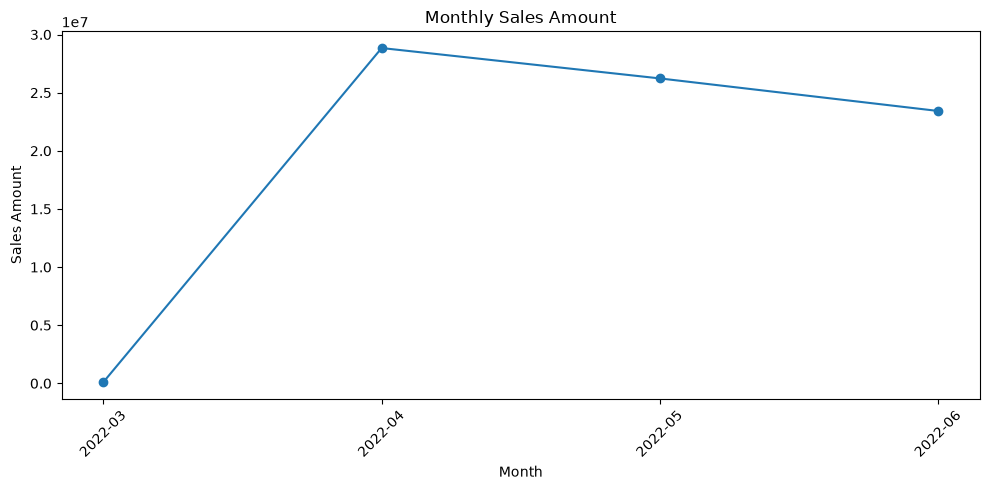

In [45]:
# ==========================================
# STEP 12.2
# MONTHLY SALES TREND
# ==========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales["order_month"],
    monthly_sales["sales_amount"],
    marker="o"
)

plt.title("Monthly Sales Amount")
plt.xlabel("Month")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [46]:
# ==========================================
# STEP 12.3
# MONTHLY SALES SUMMARY
# ==========================================

display(
    monthly_sales[
        [
            "order_month",
            "orders",
            "order_lines",
            "units",
            "sales_amount",
            "avg_order_value",
            "sales_change_pct"
        ]
    ].round(2)
)

,order_month,orders,order_lines,units,sales_amount,avg_order_value,sales_change_pct
0,2022-03,158,171,156,101683.85,643.57,NaN
1,2022-04,45858,49065,44206,28838708.32,628.87,28261.15
2,2022-05,39221,42037,38009,26225004.75,668.65,-9.06
3,2022-06,35141,37696,34275,23424646.38,666.59,-10.68


In [47]:
# ==========================================
# STEP 12.4
# BEST AND WORST MONTH
# ==========================================

best_sales_month = monthly_sales.loc[
    monthly_sales["sales_amount"].idxmax()
]

best_orders_month = monthly_sales.loc[
    monthly_sales["orders"].idxmax()
]

print("=== BEST MONTH BY SALES AMOUNT ===")
print(f"Month: {best_sales_month['order_month']}")
print(f"Sales Amount: {best_sales_month['sales_amount']:,.2f}")
print(f"Orders: {best_sales_month['orders']:,}")
print(f"Units: {best_sales_month['units']:,}")

print("\n=== BEST MONTH BY ORDERS ===")
print(f"Month: {best_orders_month['order_month']}")
print(f"Orders: {best_orders_month['orders']:,}")
print(f"Sales Amount: {best_orders_month['sales_amount']:,.2f}")
print(f"Units: {best_orders_month['units']:,}")

=== BEST MONTH BY SALES AMOUNT ===
Month: 2022-04
Sales Amount: 28,838,708.32
Orders: 45,858
Units: 44,206

=== BEST MONTH BY ORDERS ===
Month: 2022-04
Orders: 45,858
Sales Amount: 28,838,708.32
Units: 44,206


In [48]:
# ==========================================
# STEP 13
# MONTHLY PERFORMANCE COMPARISON
# ==========================================

monthly_sales_display = monthly_sales.copy()

monthly_sales_display["sales_amount"] = (
    monthly_sales_display["sales_amount"].round(2)
)

monthly_sales_display["avg_order_value"] = (
    monthly_sales_display["avg_order_value"].round(2)
)

monthly_sales_display["sales_change_pct"] = (
    monthly_sales_display["sales_change_pct"].round(2)
)

display(monthly_sales_display)

,order_month,orders,order_lines,units,sales_amount,avg_order_value,sales_change_pct
0,2022-03,158,171,156,101683.85,643.57,NaN
1,2022-04,45858,49065,44206,28838708.32,628.87,28261.15
2,2022-05,39221,42037,38009,26225004.75,668.65,-9.06
3,2022-06,35141,37696,34275,23424646.38,666.59,-10.68


In [49]:
# ==========================================
# STEP 13.1
# MONTHLY SALES RANKING
# ==========================================

monthly_sales_ranking = (
    monthly_sales
    .sort_values("sales_amount", ascending=False)
    [
        [
            "order_month",
            "orders",
            "units",
            "sales_amount",
            "avg_order_value",
            "sales_change_pct"
        ]
    ]
)

display(
    monthly_sales_ranking.round(2)
)

,order_month,orders,units,sales_amount,avg_order_value,sales_change_pct
1,2022-04,45858,44206,28838708.32,628.87,28261.15
2,2022-05,39221,38009,26225004.75,668.65,-9.06
3,2022-06,35141,34275,23424646.38,666.59,-10.68
0,2022-03,158,156,101683.85,643.57,NaN


In [50]:
# ==========================================
# STEP 14
# CATEGORY PERFORMANCE ANALYSIS
# ==========================================

category_analysis = (
    df_clean
    .groupby("category")
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum")
    )
    .reset_index()
)

category_analysis["avg_order_value"] = (
    category_analysis["sales_amount"]
    / category_analysis["orders"]
)

category_analysis = (
    category_analysis
    .sort_values("sales_amount", ascending=False)
)

display(category_analysis.round(2))

,category,orders,order_lines,units,sales_amount,avg_order_value
5,Set,47845,50281,45287,39202022.03,819.35
8,kurta,46561,49874,45044,21299013.70,457.44
7,Western Dress,14994,15500,13943,11216072.69,748.04
6,Top,10155,10622,9903,5347792.30,526.62
3,Ethnic Dress,1148,1159,1053,791217.66,689.21
0,Blouse,897,926,863,458408.18,511.05
1,Bottom,410,440,398,150667.98,367.48
4,Saree,144,164,152,123933.76,860.65
2,Dupatta,2,3,3,915.00,457.50


In [51]:
# ==========================================
# STEP 14.1
# CATEGORY CANCELLATION RATE
# ==========================================

category_cancellation = (
    df_clean
    .groupby("category")
    .agg(
        total_orders=("order_id", "nunique"),
        cancelled_orders=(
            "is_cancelled",
            lambda x: df_clean.loc[x.index, "order_id"]
            .loc[x]
            .nunique()
        )
    )
    .reset_index()
)

category_cancellation["cancellation_rate"] = (
    category_cancellation["cancelled_orders"]
    / category_cancellation["total_orders"]
    * 100
)

category_cancellation = (
    category_cancellation
    .sort_values("cancellation_rate", ascending=False)
)

display(category_cancellation.round(2))

,category,total_orders,cancelled_orders,cancellation_rate
8,kurta,46561,6818,14.64
5,Set,47845,6990,14.61
4,Saree,144,21,14.58
7,Western Dress,14994,2070,13.81
1,Bottom,410,54,13.17
0,Blouse,897,113,12.60
3,Ethnic Dress,1148,144,12.54
6,Top,10155,1231,12.12
2,Dupatta,2,0,0.00


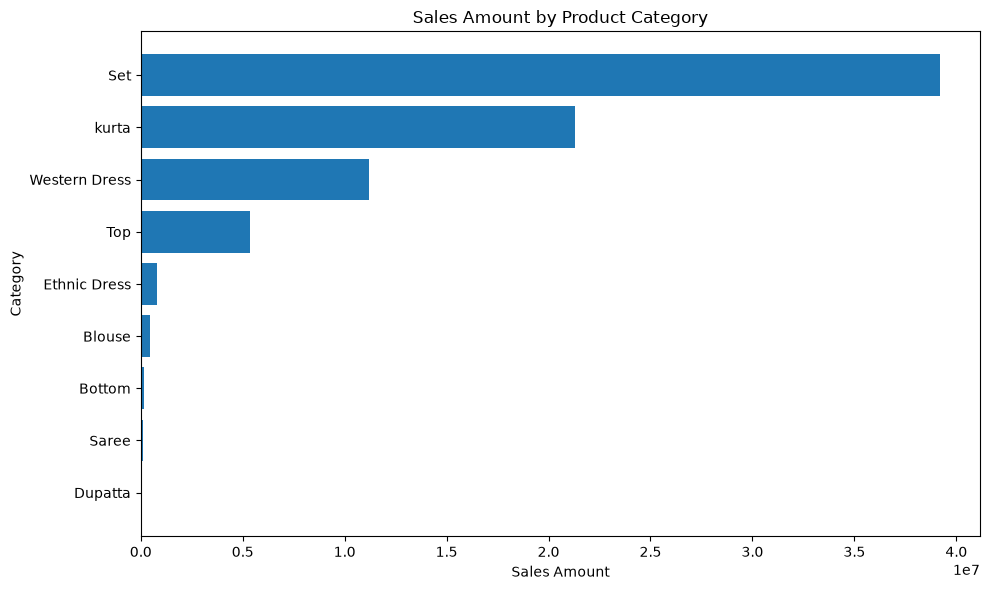

In [52]:
# ==========================================
# STEP 14.2
# CATEGORY SALES AMOUNT CHART
# ==========================================

import matplotlib.pyplot as plt

category_chart = (
    category_analysis
    .sort_values("sales_amount", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    category_chart["category"],
    category_chart["sales_amount"]
)

plt.title("Sales Amount by Product Category")
plt.xlabel("Sales Amount")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [53]:
# ==========================================
# STEP 14.3
# CATEGORY SALES SHARE
# ==========================================

category_analysis["sales_share_pct"] = (
    category_analysis["sales_amount"]
    / category_analysis["sales_amount"].sum()
    * 100
)

category_share = (
    category_analysis
    [
        [
            "category",
            "sales_amount",
            "sales_share_pct",
            "orders",
            "avg_order_value"
        ]
    ]
    .sort_values("sales_share_pct", ascending=False)
)

display(
    category_share.round(2)
)

,category,sales_amount,sales_share_pct,orders,avg_order_value
5,Set,39202022.03,49.88,47845,819.35
8,kurta,21299013.70,27.10,46561,457.44
7,Western Dress,11216072.69,14.27,14994,748.04
6,Top,5347792.30,6.80,10155,526.62
3,Ethnic Dress,791217.66,1.01,1148,689.21
0,Blouse,458408.18,0.58,897,511.05
1,Bottom,150667.98,0.19,410,367.48
4,Saree,123933.76,0.16,144,860.65
2,Dupatta,915.00,0.00,2,457.50


In [54]:
fulfilment_analysis = (
    df_clean
    .groupby("fulfilment")
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum")
    )
    .reset_index()
)

fulfilment_analysis["avg_order_value"] = (
    fulfilment_analysis["sales_amount"]
    / fulfilment_analysis["orders"]
)

fulfilment_analysis["sales_share_pct"] = (
    fulfilment_analysis["sales_amount"]
    / fulfilment_analysis["sales_amount"].sum()
    * 100
)

display(
    fulfilment_analysis
    .sort_values("sales_amount", ascending=False)
    .round(2)
)

,fulfilment,orders,order_lines,units,sales_amount,avg_order_value,sales_share_pct
0,Amazon,84002,89692,84084,54319516.0,646.65,69.12
1,Merchant,36376,39277,32562,24270527.3,667.21,30.88


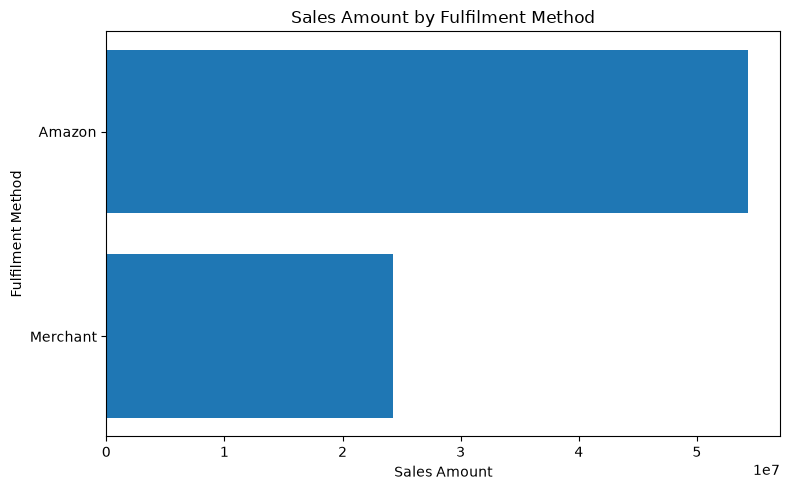

In [55]:
fulfilment_chart = (
    fulfilment_analysis
    .sort_values("sales_amount", ascending=True)
)

plt.figure(figsize=(8, 5))

plt.barh(
    fulfilment_chart["fulfilment"],
    fulfilment_chart["sales_amount"]
)

plt.title("Sales Amount by Fulfilment Method")
plt.xlabel("Sales Amount")
plt.ylabel("Fulfilment Method")

plt.tight_layout()
plt.show()

In [56]:
fulfilment_cancellation = (
    df_clean
    .groupby("fulfilment")
    .agg(
        total_orders=("order_id", "nunique"),
        cancelled_orders=(
            "is_cancelled",
            lambda x: df_clean.loc[x.index, "order_id"].loc[x].nunique()
        )
    )
    .reset_index()
)

fulfilment_cancellation["cancellation_rate_pct"] = (
    fulfilment_cancellation["cancelled_orders"]
    / fulfilment_cancellation["total_orders"]
    * 100
)

display(
    fulfilment_cancellation
    .sort_values("cancellation_rate_pct", ascending=False)
    .round(2)
)

,fulfilment,total_orders,cancelled_orders,cancellation_rate_pct
1,Merchant,36376,6382,17.54
0,Amazon,84002,10803,12.86


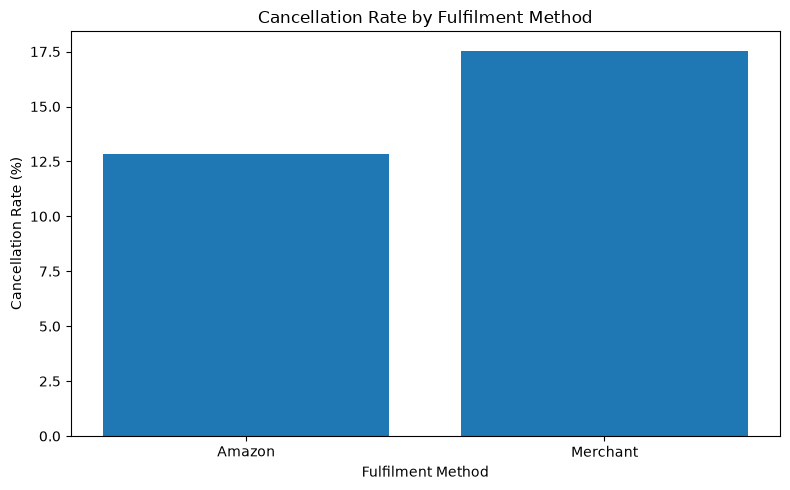

In [57]:
plt.figure(figsize=(8, 5))

plt.bar(
    fulfilment_cancellation["fulfilment"],
    fulfilment_cancellation["cancellation_rate_pct"]
)

plt.title("Cancellation Rate by Fulfilment Method")
plt.xlabel("Fulfilment Method")
plt.ylabel("Cancellation Rate (%)")

plt.tight_layout()
plt.show()

In [58]:
sales_channel_analysis = (
    df_clean
    .groupby("sales_channel")
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum")
    )
    .reset_index()
)

sales_channel_analysis["avg_order_value"] = (
    sales_channel_analysis["sales_amount"]
    / sales_channel_analysis["orders"]
)

sales_channel_analysis["sales_share_pct"] = (
    sales_channel_analysis["sales_amount"]
    / sales_channel_analysis["sales_amount"].sum()
    * 100
)

display(
    sales_channel_analysis
    .sort_values("sales_amount", ascending=False)
    .round(2)
)

,sales_channel,orders,order_lines,units,sales_amount,avg_order_value,sales_share_pct
0,Amazon.in,120254,128845,116479,78590043.3,653.53,100.0
1,Non-Amazon,124,124,167,0.0,0.00,0.0


In [59]:
shipping_analysis = (
    df_clean
    .groupby("ship_service_level")
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum")
    )
    .reset_index()
)

shipping_analysis["avg_order_value"] = (
    shipping_analysis["sales_amount"]
    / shipping_analysis["orders"]
)

shipping_analysis["sales_share_pct"] = (
    shipping_analysis["sales_amount"]
    / shipping_analysis["sales_amount"].sum()
    * 100
)

display(
    shipping_analysis
    .sort_values("sales_amount", ascending=False)
    .round(2)
)

,ship_service_level,orders,order_lines,units,sales_amount,avg_order_value,sales_share_pct
0,Expedited,82922,88609,83001,54282548.0,654.62,69.07
1,Standard,37456,40360,33645,24307495.3,648.96,30.93


In [60]:
shipping_cancellation = (
    df_clean
    .groupby("ship_service_level")
    .agg(
        total_orders=("order_id", "nunique"),
        cancelled_orders=(
            "is_cancelled",
            lambda x: df_clean.loc[x.index, "order_id"].loc[x].nunique()
        )
    )
    .reset_index()
)

shipping_cancellation["cancellation_rate_pct"] = (
    shipping_cancellation["cancelled_orders"]
    / shipping_cancellation["total_orders"]
    * 100
)

display(
    shipping_cancellation
    .sort_values("cancellation_rate_pct", ascending=False)
    .round(2)
)

,ship_service_level,total_orders,cancelled_orders,cancellation_rate_pct
1,Standard,37456,6429,17.16
0,Expedited,82922,10756,12.97


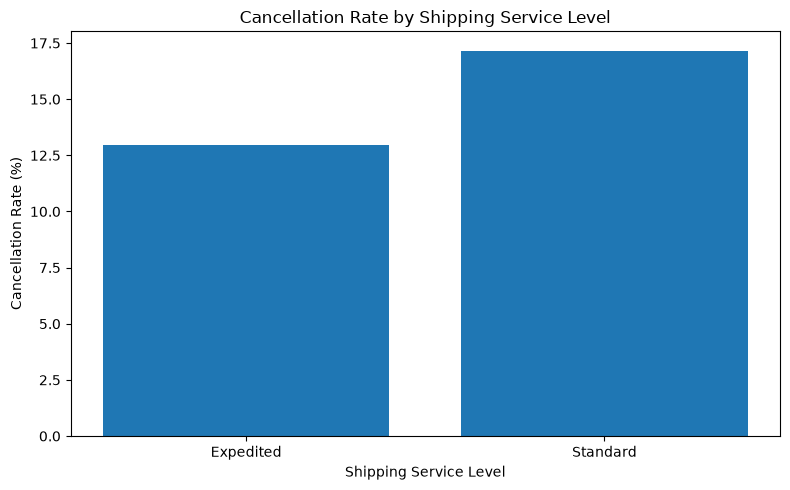

In [61]:
plt.figure(figsize=(8, 5))

plt.bar(
    shipping_cancellation["ship_service_level"],
    shipping_cancellation["cancellation_rate_pct"]
)

plt.title("Cancellation Rate by Shipping Service Level")
plt.xlabel("Shipping Service Level")
plt.ylabel("Cancellation Rate (%)")

plt.tight_layout()
plt.show()

In [62]:
fulfilment_shipping = (
    df_clean
    .groupby(["fulfilment", "ship_service_level"])
    .agg(
        total_orders=("order_id", "nunique"),
        cancelled_orders=(
            "is_cancelled",
            lambda x: df_clean.loc[x.index, "order_id"].loc[x].nunique()
        ),
        sales_amount=("amount", "sum")
    )
    .reset_index()
)

fulfilment_shipping["cancellation_rate_pct"] = (
    fulfilment_shipping["cancelled_orders"]
    / fulfilment_shipping["total_orders"]
    * 100
)

fulfilment_shipping["avg_order_value"] = (
    fulfilment_shipping["sales_amount"]
    / fulfilment_shipping["total_orders"]
)

display(
    fulfilment_shipping
    .sort_values("cancellation_rate_pct", ascending=False)
    .round(2)
)

,fulfilment,ship_service_level,total_orders,cancelled_orders,sales_amount,cancellation_rate_pct,avg_order_value
2,Merchant,Standard,36376,6382,24270527.3,17.54,667.21
0,Amazon,Expedited,82922,10756,54282548.0,12.97,654.62
1,Amazon,Standard,1080,47,36968.0,4.35,34.23


In [63]:
amazon_standard = df_clean[
    (df_clean["fulfilment"] == "Amazon") &
    (df_clean["ship_service_level"] == "Standard")
]

print("Rows:", len(amazon_standard))
print("Unique orders:", amazon_standard["order_id"].nunique())
print("Total units:", amazon_standard["qty"].sum())
print("Sales Amount:", amazon_standard["amount"].sum())

print("\nStatus distribution:")
display(
    amazon_standard["status"]
    .value_counts()
)

print("\nAmount statistics:")
display(
    amazon_standard["amount"]
    .describe()
)

Rows: 1083
Unique orders: 1080
Total units: 1083
Sales Amount: 36968.0

Status distribution:


status
Shipped      1025
Cancelled      48
Shipping        8
Pending         2
Name: count, dtype: int64


Amount statistics:


count     916.000000
mean       40.358079
std       162.097746
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max      1432.000000
Name: amount, dtype: float64

In [64]:
print("Amount = 0:")
print((amazon_standard["amount"] == 0).sum())

print("\nQty = 0:")
print((amazon_standard["qty"] == 0).sum())

print("\nMissing Amount:")
print(amazon_standard["amount"].isna().sum())

print("\nMissing Qty:")
print(amazon_standard["qty"].isna().sum())

Amount = 0:
855

Qty = 0:
43

Missing Amount:
167

Missing Qty:
0


In [65]:
amazon_standard_zero = amazon_standard[
    amazon_standard["amount"] == 0
]

zero_amount_status = (
    amazon_standard_zero
    .groupby("status")
    .agg(
        rows=("order_id", "size"),
        orders=("order_id", "nunique"),
        units=("qty", "sum")
    )
    .reset_index()
    .sort_values("rows", ascending=False)
)

display(zero_amount_status)

,status,rows,orders,units
1,Shipped,853,853,853
0,Pending,2,2,2


In [66]:
amazon_standard_missing = amazon_standard[
    amazon_standard["amount"].isna()
]

missing_amount_status = (
    amazon_standard_missing
    .groupby("status")
    .agg(
        rows=("order_id", "size"),
        orders=("order_id", "nunique")
    )
    .reset_index()
    .sort_values("rows", ascending=False)
)

display(missing_amount_status)

,status,rows,orders
1,Shipped,115,115
0,Cancelled,44,43
2,Shipping,8,8


In [67]:
state_analysis = (
    df_clean
    .groupby("ship_state")
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum")
    )
    .reset_index()
)

state_analysis["avg_order_value"] = (
    state_analysis["sales_amount"]
    / state_analysis["orders"]
)

state_analysis["sales_share_pct"] = (
    state_analysis["sales_amount"]
    / state_analysis["sales_amount"].sum()
    * 100
)

state_analysis = state_analysis.sort_values(
    "sales_amount",
    ascending=False
)

display(
    state_analysis.head(20).round(2)
)

,ship_state,orders,order_lines,units,sales_amount,avg_order_value,sales_share_pct
28,MAHARASHTRA,20780,22259,20327,13334595.14,641.70,16.97
23,KARNATAKA,16182,17325,15901,10481114.37,647.70,13.34
57,TELANGANA,10405,11330,10253,6916615.65,664.74,8.80
59,UTTAR PRADESH,10062,10637,9498,6816109.08,677.41,8.68
56,TAMIL NADU,10519,11483,10412,6515650.11,619.42,8.29
14,DELHI,6359,6782,6156,4235215.97,666.02,5.39
24,KERALA,6105,6584,5813,3830227.58,627.39,4.87
61,WEST BENGAL,5653,5962,5318,3507880.44,620.53,4.46
1,ANDHRA PRADESH,4979,5430,4819,3219831.72,646.68,4.10
19,HARYANA,4142,4415,4066,2882092.99,695.82,3.67


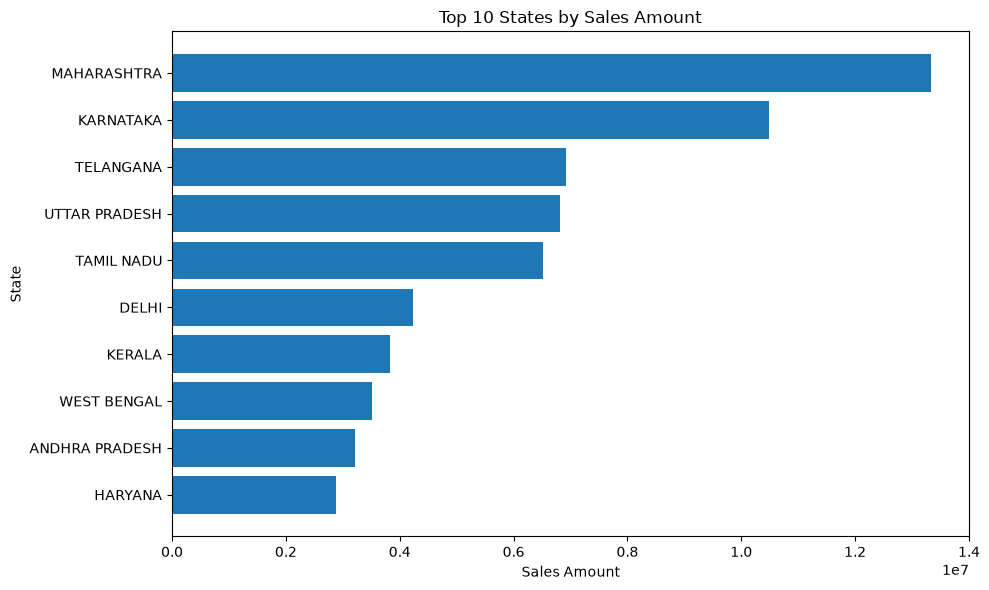

In [68]:
top_states = (
    state_analysis
    .head(10)
    .sort_values("sales_amount", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_states["ship_state"],
    top_states["sales_amount"]
)

plt.title("Top 10 States by Sales Amount")
plt.xlabel("Sales Amount")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [69]:
top_5_states = state_analysis.head(5)

top_5_sales_share = top_5_states["sales_share_pct"].sum()

print(
    f"Top 5 states account for {top_5_sales_share:.2f}% "
    "of total Sales Amount."
)

Top 5 states account for 56.08% of total Sales Amount.


In [70]:
state_cancellation = (
    df_clean
    .groupby("ship_state")
    .agg(
        total_orders=("order_id", "nunique"),
        cancelled_orders=(
            "is_cancelled",
            lambda x: df_clean.loc[x.index, "order_id"].loc[x].nunique()
        )
    )
    .reset_index()
)

state_cancellation["cancellation_rate_pct"] = (
    state_cancellation["cancelled_orders"]
    / state_cancellation["total_orders"]
    * 100
)

state_cancellation = state_cancellation.sort_values(
    "total_orders",
    ascending=False
)

display(
    state_cancellation.head(20).round(2)
)

,ship_state,total_orders,cancelled_orders,cancellation_rate_pct
28,MAHARASHTRA,20780,2778,13.37
23,KARNATAKA,16182,2097,12.96
56,TAMIL NADU,10519,1440,13.69
57,TELANGANA,10405,1505,14.46
59,UTTAR PRADESH,10062,1531,15.22
14,DELHI,6359,828,13.02
24,KERALA,6105,1086,17.79
61,WEST BENGAL,5653,846,14.97
1,ANDHRA PRADESH,4979,815,16.37
18,Gujarat,4169,556,13.34


In [71]:
state_cancellation_filtered = (
    state_cancellation[
        state_cancellation["total_orders"] >= 1000
    ]
    .sort_values(
        "cancellation_rate_pct",
        ascending=False
    )
)

display(
    state_cancellation_filtered.round(2)
)

,ship_state,total_orders,cancelled_orders,cancellation_rate_pct
24,KERALA,6105,1086,17.79
8,BIHAR,1989,327,16.44
1,ANDHRA PRADESH,4979,815,16.37
22,JHARKHAND,1382,226,16.35
39,ODISHA,2000,322,16.10
27,MADHYA PRADESH,2375,365,15.37
5,ASSAM,1601,245,15.30
60,UTTARAKHAND,1480,226,15.27
59,UTTAR PRADESH,10062,1531,15.22
61,WEST BENGAL,5653,846,14.97


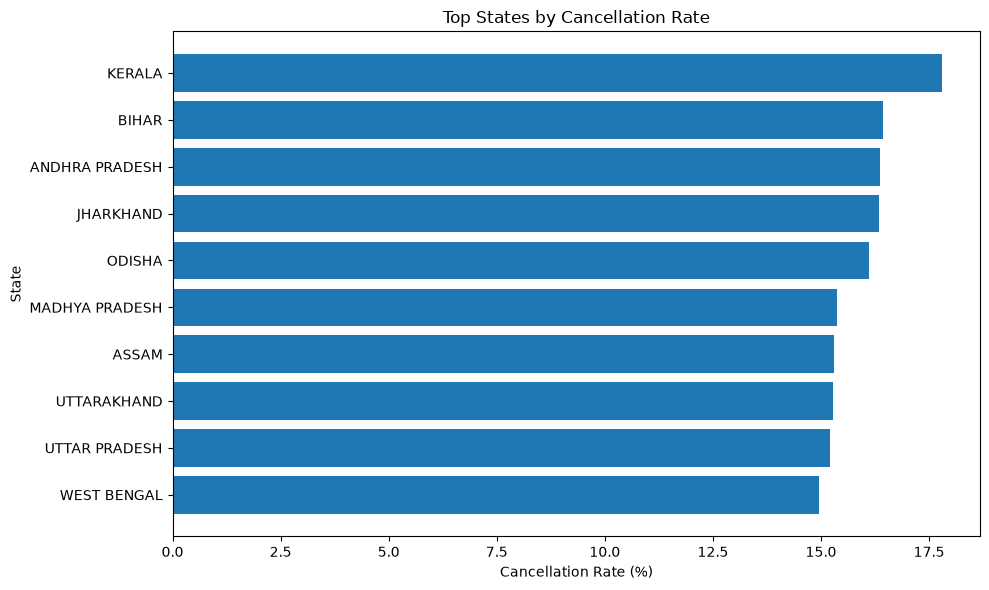

In [72]:
top_cancellation_states = (
    state_cancellation_filtered
    .head(10)
    .sort_values(
        "cancellation_rate_pct",
        ascending=True
    )
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_cancellation_states["ship_state"],
    top_cancellation_states["cancellation_rate_pct"]
)

plt.title("Top States by Cancellation Rate")
plt.xlabel("Cancellation Rate (%)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [73]:
sku_analysis = (
    df_clean
    .groupby(["sku", "category"])
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum")
    )
    .reset_index()
)

sku_analysis["avg_order_value"] = (
    sku_analysis["sales_amount"] /
    sku_analysis["orders"]
)

sku_analysis["sales_share_pct"] = (
    sku_analysis["sales_amount"] /
    sku_analysis["sales_amount"].sum() * 100
)

top_skus = (
    sku_analysis
    .sort_values("sales_amount", ascending=False)
    .head(20)
)

display(
    top_skus.round(2)
)

,sku,category,orders,order_lines,units,sales_amount,avg_order_value,sales_share_pct
1346,J0230-SKD-M,Set,506,506,467,526536.20,1040.59,0.67
4548,JNE3797-KR-L,Western Dress,773,773,661,524581.77,678.63,0.67
1347,J0230-SKD-S,Set,452,452,421,479937.14,1061.81,0.61
4549,JNE3797-KR-M,Western Dress,657,657,561,454290.16,691.46,0.58
4550,JNE3797-KR-S,Western Dress,587,587,503,407302.57,693.87,0.52
4551,JNE3797-KR-XL,Western Dress,474,474,415,332155.24,700.75,0.42
1345,J0230-SKD-L,Set,297,297,272,305616.95,1029.01,0.39
4552,JNE3797-KR-XS,Western Dress,431,431,386,303616.70,704.45,0.39
6305,SET268-KR-NP-XL,Set,386,386,373,284058.96,735.90,0.36
4554,JNE3797-KR-XXXL,Western Dress,386,386,353,276375.80,716.00,0.35


In [74]:
sku_cancellation = (
    df_clean
    .groupby(["sku", "category"])
    .agg(
        total_orders=("order_id", "nunique"),
        cancelled_orders=(
            "order_id",
            lambda x: x[df_clean.loc[x.index, "is_cancelled"]].nunique()
        ),
        sales_amount=("amount", "sum"),
        units=("qty", "sum")
    )
    .reset_index()
)

sku_cancellation["cancellation_rate_pct"] = (
    sku_cancellation["cancelled_orders"] /
    sku_cancellation["total_orders"] * 100
)

sku_cancellation_filtered = (
    sku_cancellation[
        sku_cancellation["total_orders"] >= 100
    ]
    .sort_values(
        "cancellation_rate_pct",
        ascending=False
    )
)

display(
    sku_cancellation_filtered.head(20).round(2)
)

,sku,category,total_orders,cancelled_orders,sales_amount,units,cancellation_rate_pct
3004,JNE3461-KR-L,kurta,101,28,34946.27,86,27.72
6664,SET331-KR-NP-S,Set,148,37,75796.67,121,25.00
6617,SET324-KR-NP-XS,Set,149,35,84317.08,121,23.49
2617,JNE3368-KR-XL,kurta,128,30,52149.00,116,23.44
2900,JNE3440-KR-N-M,kurta,208,48,78904.58,185,23.08
5897,SET183-KR-DH-XXXL,Set,122,28,87534.16,109,22.95
350,J0003-SET-XS,Set,252,57,149347.62,207,22.62
4090,JNE3721-KR-XXL,kurta,109,24,30538.98,91,22.02
6306,SET268-KR-NP-XS,Set,192,41,132258.48,177,21.35
3141,JNE3487-KR-XXL,kurta,105,22,32723.33,93,20.95


In [75]:
sku_risk = (
    df_clean
    .groupby(["sku", "category"])
    .agg(
        orders=("order_id", "nunique"),
        cancelled_orders=(
            "order_id",
            lambda x: x[df_clean.loc[x.index, "is_cancelled"]].nunique()
        ),
        sales_amount=("amount", "sum"),
        units=("qty", "sum")
    )
    .reset_index()
)

sku_risk["cancellation_rate_pct"] = (
    sku_risk["cancelled_orders"] /
    sku_risk["orders"] * 100
)

sku_risk_filtered = sku_risk[
    sku_risk["orders"] >= 100
].copy()

sales_threshold = sku_risk_filtered["sales_amount"].quantile(0.75)
cancellation_threshold = sku_risk_filtered["cancellation_rate_pct"].quantile(0.75)

sku_risk_filtered["risk_segment"] = "Normal"

sku_risk_filtered.loc[
    (sku_risk_filtered["sales_amount"] >= sales_threshold) &
    (sku_risk_filtered["cancellation_rate_pct"] >= cancellation_threshold),
    "risk_segment"
] = "High Sales + High Cancellation"

high_risk_skus = (
    sku_risk_filtered[
        sku_risk_filtered["risk_segment"] == "High Sales + High Cancellation"
    ]
    .sort_values(
        ["sales_amount", "cancellation_rate_pct"],
        ascending=[False, False]
    )
)

display(
    high_risk_skus.round(2)
)

,sku,category,orders,cancelled_orders,sales_amount,units,cancellation_rate_pct,risk_segment
4550,JNE3797-KR-S,Western Dress,587,99,407302.57,503,16.87,High Sales + High Cancellation
6304,SET268-KR-NP-S,Set,387,71,267030.48,350,18.35,High Sales + High Cancellation
1348,J0230-SKD-XL,Set,241,40,259032.58,221,16.60,High Sales + High Cancellation
1349,J0230-SKD-XS,Set,228,40,221741.86,197,17.54,High Sales + High Cancellation
1769,J0341-DR-S,Western Dress,278,53,214934.45,244,19.06,High Sales + High Cancellation
348,J0003-SET-S,Set,334,66,193079.79,281,19.76,High Sales + High Cancellation
6614,SET324-KR-NP-M,Set,305,55,171020.92,268,18.03,High Sales + High Cancellation
347,J0003-SET-M,Set,284,53,169574.52,235,18.66,High Sales + High Cancellation
350,J0003-SET-XS,Set,252,57,149347.62,207,22.62,High Sales + High Cancellation
386,J0008-SKD-XS,Set,141,29,135530.82,124,20.57,High Sales + High Cancellation


In [76]:
size_analysis = (
    df_clean
    .groupby("size")
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum"),
        cancelled_orders=(
            "order_id",
            lambda x: x[df_clean.loc[x.index, "is_cancelled"]].nunique()
        )
    )
    .reset_index()
)

size_analysis["avg_order_value"] = (
    size_analysis["sales_amount"] /
    size_analysis["orders"]
)

size_analysis["cancellation_rate_pct"] = (
    size_analysis["cancelled_orders"] /
    size_analysis["orders"] * 100
)

size_analysis["sales_share_pct"] = (
    size_analysis["sales_amount"] /
    size_analysis["sales_amount"].sum() * 100
)

display(
    size_analysis
    .sort_values("sales_amount", ascending=False)
    .round(2)
)

,size,orders,order_lines,units,sales_amount,cancelled_orders,avg_order_value,cancellation_rate_pct,sales_share_pct
6,M,21722,22709,20446,13905591.37,3233,640.16,14.88,17.69
5,L,21058,22130,20000,13234886.19,3003,628.50,14.26,16.84
8,XL,19896,20875,18922,12464026.86,2744,626.46,13.79,15.86
10,XXL,17164,18096,16516,10636288.45,2277,619.69,13.27,13.53
7,S,16336,17090,15331,10629210.18,2492,650.66,15.25,13.52
0,3XL,13755,14815,13523,9156614.68,1716,665.69,12.48,11.65
9,XS,10533,11161,9943,7022375.20,1774,666.70,16.84,8.94
3,6XL,681,738,688,576249.33,69,846.18,10.13,0.73
2,5XL,526,550,513,425156.63,52,808.28,9.89,0.54
1,4XL,394,427,398,334451.64,42,848.86,10.66,0.43


In [77]:
size_category_analysis = (
    df_clean
    .groupby(["category", "size"])
    .agg(
        orders=("order_id", "nunique"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum"),
        cancelled_orders=(
            "order_id",
            lambda x: x[df_clean.loc[x.index, "is_cancelled"]].nunique()
        )
    )
    .reset_index()
)

size_category_analysis["cancellation_rate_pct"] = (
    size_category_analysis["cancelled_orders"] /
    size_category_analysis["orders"] * 100
)

size_category_filtered = (
    size_category_analysis[
        size_category_analysis["orders"] >= 500
    ]
    .sort_values(
        "cancellation_rate_pct",
        ascending=False
    )
)

display(
    size_category_filtered.round(2)
)

,category,size,orders,units,sales_amount,cancelled_orders,cancellation_rate_pct
31,Set,XS,5259,4882,4261845.52,913,17.36
55,kurta,XS,2954,2783,1238176.34,509,17.23
43,Western Dress,S,2184,1962,1602174.85,353,16.16
52,kurta,M,8164,7713,3547070.45,1271,15.57
53,kurta,S,5480,5157,2351823.31,847,15.46
45,Western Dress,XS,1405,1280,999625.05,217,15.44
29,Set,S,7266,6708,5835237.31,1115,15.35
28,Set,M,9064,8356,7302994.75,1365,15.06
51,kurta,L,8456,8043,3729872.84,1261,14.91
38,Top,XS,921,870,449973.47,137,14.88


In [78]:
category_totals = (
    df_clean
    .groupby("category")
    .agg(
        category_orders=("order_id", "nunique"),
        category_cancelled_orders=(
            "order_id",
            lambda x: x[df_clean.loc[x.index, "is_cancelled"]].nunique()
        )
    )
    .reset_index()
)

category_totals["category_cancellation_rate_pct"] = (
    category_totals["category_cancelled_orders"] /
    category_totals["category_orders"] * 100
)

size_category_index = size_category_filtered.merge(
    category_totals[
        ["category", "category_cancellation_rate_pct"]
    ],
    on="category",
    how="left"
)

size_category_index["cancellation_index"] = (
    size_category_index["cancellation_rate_pct"] /
    size_category_index["category_cancellation_rate_pct"]
)

display(
    size_category_index[
        [
            "category",
            "size",
            "orders",
            "cancellation_rate_pct",
            "category_cancellation_rate_pct",
            "cancellation_index"
        ]
    ]
    .sort_values("cancellation_index", ascending=False)
    .round(2)
)

,category,size,orders,cancellation_rate_pct,category_cancellation_rate_pct,cancellation_index
9,Top,XS,921,14.88,12.12,1.23
0,Set,XS,5259,17.36,14.61,1.19
1,kurta,XS,2954,17.23,14.64,1.18
2,Western Dress,S,2184,16.16,13.81,1.17
5,Western Dress,XS,1405,15.44,13.81,1.12
3,kurta,M,8164,15.57,14.64,1.06
20,Top,S,1197,12.87,12.12,1.06
4,kurta,S,5480,15.46,14.64,1.06
6,Set,S,7266,15.35,14.61,1.05
21,Top,M,1773,12.69,12.12,1.05


In [79]:
promotion_analysis = (
    df_clean
    .groupby("has_promotion")
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum"),
        cancelled_orders=(
            "order_id",
            lambda x: x[df_clean.loc[x.index, "is_cancelled"]].nunique()
        )
    )
    .reset_index()
)

promotion_analysis["avg_order_value"] = (
    promotion_analysis["sales_amount"] /
    promotion_analysis["orders"]
)

promotion_analysis["cancellation_rate_pct"] = (
    promotion_analysis["cancelled_orders"] /
    promotion_analysis["orders"] * 100
)

promotion_analysis["sales_share_pct"] = (
    promotion_analysis["sales_amount"] /
    promotion_analysis["sales_amount"].sum() * 100
)

promotion_analysis["promotion_status"] = (
    promotion_analysis["has_promotion"]
    .map({
        True: "With Promotion",
        False: "Without Promotion"
    })
)

promotion_analysis = promotion_analysis[
    [
        "promotion_status",
        "orders",
        "order_lines",
        "units",
        "sales_amount",
        "avg_order_value",
        "cancelled_orders",
        "cancellation_rate_pct",
        "sales_share_pct"
    ]
]

display(
    promotion_analysis.round(2)
)

,promotion_status,orders,order_lines,units,sales_amount,avg_order_value,cancelled_orders,cancellation_rate_pct,sales_share_pct
0,Without Promotion,46937,49150,36798,25004243.3,532.72,16914,36.04,31.82
1,With Promotion,73464,79819,79848,53585800.0,729.42,271,0.37,68.18


In [80]:
promotion_status_check = (
    df_clean
    .groupby(["has_promotion", "status_group"])
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum")
    )
    .reset_index()
)

promotion_status_check["promotion_status"] = (
    promotion_status_check["has_promotion"]
    .map({
        True: "With Promotion ID",
        False: "Without Promotion ID"
    })
)

display(
    promotion_status_check[
        [
            "promotion_status",
            "status_group",
            "orders",
            "order_lines",
            "units",
            "sales_amount"
        ]
    ]
    .sort_values(
        ["promotion_status", "orders"],
        ascending=[True, False]
    )
)

,promotion_status,status_group,orders,order_lines,units,sales_amount
5,With Promotion ID,Completed / Shipped,70499,76629,76900,51645402.0
7,With Promotion ID,Returned / Failed Delivery,1996,2111,2136,1387692.0
6,With Promotion ID,Pending,698,784,786,534629.0
4,With Promotion ID,Cancelled,271,295,26,18077.0
1,Without Promotion ID,Completed / Shipped,29863,30949,31004,18015256.0
0,Without Promotion ID,Cancelled,16914,18034,5631,6901207.3
2,Without Promotion ID,Pending,156,163,162,87780.0
3,Without Promotion ID,Returned / Failed Delivery,4,4,1,0.0


In [81]:
courier_analysis = (
    df_clean
    .groupby(["courier_status", "status_group"])
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum")
    )
    .reset_index()
)

display(
    courier_analysis
    .sort_values(
        ["courier_status", "orders"],
        ascending=[True, False]
    )
    .round(2)
)

,courier_status,status_group,orders,order_lines,units,sales_amount
0,Cancelled,Cancelled,5579,5837,0,0.0
1,Cancelled,Completed / Shipped,84,93,0,0.0
2,Cancelled,Pending,2,2,0,0.0
3,Shipped,Completed / Shipped,100227,107362,107746,69660658.0
5,Shipped,Returned / Failed Delivery,1997,2112,2137,1387692.0
4,Shipped,Pending,8,10,10,7679.0
6,Unshipped,Cancelled,5226,5631,5657,3729112.0
8,Unshipped,Pending,854,935,938,614730.0
7,Unshipped,Completed / Shipped,115,115,158,0.0


In [82]:
b2b_analysis = (
    df_clean
    .groupby("b2b")
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum"),
        cancelled_orders=(
            "order_id",
            lambda x: x[df_clean.loc[x.index, "is_cancelled"]].nunique()
        )
    )
    .reset_index()
)

b2b_analysis["avg_order_value"] = (
    b2b_analysis["sales_amount"] / b2b_analysis["orders"]
)

b2b_analysis["cancellation_rate_pct"] = (
    b2b_analysis["cancelled_orders"] /
    b2b_analysis["orders"] * 100
)

b2b_analysis["sales_share_pct"] = (
    b2b_analysis["sales_amount"] /
    b2b_analysis["sales_amount"].sum() * 100
)

b2b_analysis["customer_type"] = (
    b2b_analysis["b2b"]
    .map({
        True: "B2B",
        False: "B2C"
    })
)

display(
    b2b_analysis[
        [
            "customer_type",
            "orders",
            "order_lines",
            "units",
            "sales_amount",
            "avg_order_value",
            "cancelled_orders",
            "cancellation_rate_pct",
            "sales_share_pct"
        ]
    ].round(2)
)

,customer_type,orders,order_lines,units,sales_amount,avg_order_value,cancelled_orders,cancellation_rate_pct,sales_share_pct
0,B2C,119584,128098,115806,77998822.51,652.25,17119,14.32,99.25
1,B2B,794,871,840,591220.79,744.61,66,8.31,0.75


# Executive Summary & Business Insights

## Project Overview

This analysis evaluates ecommerce sales performance, order behaviour, product performance, fulfilment operations and cancellation patterns using the Amazon Sales dataset.

The analysis focuses on:
- Sales performance
- Order volume and customer behaviour
- Product and category performance
- Regional performance
- Fulfilment and shipping operations
- Cancellation patterns
- Data quality and business limitations

## Key Business Insights

### 1. Sales are highly concentrated in a small number of product categories

The Set category generated approximately 49.9% of recorded Sales Amount, followed by kurta at 27.1% and Western Dress at 14.3%.

Together, these three categories account for approximately 91.3% of recorded Sales Amount.

This indicates a highly concentrated product mix, with a relatively small number of categories contributing the majority of sales.

---

### 2. April was the strongest full month in the dataset

April generated approximately 28.8M in Sales Amount and represented the strongest full month in the available period.

Sales decreased by approximately 9.1% in May and another 10.7% in June.

Average Order Value increased during May and June, indicating that the decline in Sales Amount was primarily associated with lower order volume rather than lower average order value.

March contains only one day of data and was therefore excluded from meaningful month-over-month comparisons.

---

### 3. Order cancellations represent an important operational issue

The overall cancellation rate is approximately 14.3%.

Cancellation rates differ across fulfilment methods and geographic regions.

Merchant fulfilment has a cancellation rate of approximately 17.5%, compared with 12.9% for Amazon fulfilment.

These results indicate that fulfilment performance should be monitored as part of operational analysis. However, the dataset does not contain sufficient information to determine the underlying causes of the difference.

---

### 4. Regional performance is concentrated

The five largest states by Sales Amount account for approximately 56.1% of recorded Sales Amount.

Maharashtra is the largest market by Sales Amount, followed by Karnataka, Telangana, Uttar Pradesh and Tamil Nadu.

Cancellation rates also vary between states, suggesting that operational monitoring may benefit from a regional perspective rather than relying only on overall performance metrics.

The dataset does not contain enough operational information to determine why cancellation rates differ between regions.

---

### 5. Several high-value products also show elevated cancellation rates

The high Sales Amount / high cancellation analysis identified several SKUs that combine relatively strong sales with above-average cancellation rates.

Examples include selected Set and Western Dress SKUs.

These products may warrant further operational investigation because they represent products with meaningful sales exposure and elevated cancellation levels.

The analysis identifies a potential priority area but does not establish the underlying cause of cancellations.

---

### 6. Selected category-size combinations show elevated cancellation patterns

The category-size analysis identified particularly elevated cancellation rates for combinations such as:

- Top – XS
- Set – XS
- kurta – XS
- Western Dress – S

After comparing each combination with its respective category baseline, Top–XS showed the strongest relative elevation.

These patterns may justify further investigation into product sizing, availability, fulfilment or customer behaviour.

The dataset does not contain sufficient information to determine the underlying cause.

---

### 7. B2B orders have a higher average order value but represent a very small share of sales

B2B orders have an Average Order Value of approximately 744.61 compared with 652.25 for B2C orders.

However, B2B represents only approximately 0.75% of recorded Sales Amount.

The B2B sample is therefore too small to support broad conclusions, but it may represent a potential segment for additional analysis if more B2B data becomes available.

---

### 8. The dataset contains important data-quality limitations

Several limitations were identified during the analysis:

- March contains only one day of data.
- Sales channel variation is extremely limited.
- Amazon Standard fulfilment contains a very high proportion of zero or missing Sales Amount values.
- Promotion IDs are strongly associated with order status, making promotion/cancellation comparisons potentially misleading.
- A small number of inconsistent Courier Status / Order Status combinations exist.
- The dataset does not contain customer identifiers, product cost, profit margin or cancellation reasons.

These limitations should be considered when interpreting the results.

# Business Recommendations

Based on the analysis, the following areas could be prioritized for further investigation:

### 1. Monitor high-volume and high-cancellation products

Prioritize SKUs that combine meaningful Sales Amount with elevated cancellation rates.

These products represent a stronger business priority than products with high cancellation rates but very low sales exposure.

### 2. Investigate regional cancellation differences

States with higher cancellation rates should be examined together with fulfilment, shipping and product-level information.

Additional operational data would be required to determine the reasons behind regional differences.

### 3. Review smaller-size product segments

Selected category-size combinations, particularly XS-related combinations, show elevated cancellation patterns.

Further investigation could include product availability, sizing information, inventory and customer return/cancellation reasons.

### 4. Review fulfilment performance

Merchant fulfilment shows a higher cancellation rate than Amazon fulfilment.

A deeper operational analysis should investigate whether differences are associated with shipping processes, inventory availability, seller performance or other operational factors.

### 5. Improve promotion data tracking

Promotion IDs should be validated before using promotion-related analysis for business decisions.

A clearly defined promotion flag would allow more reliable measurement of promotion performance.

### 6. Improve data collection

Future analysis would benefit from additional fields such as:

- Customer ID
- Product cost
- Profit margin
- Cancellation reason
- Return reason
- Promotion discount amount
- Inventory availability
- Delivery date
- Expected delivery date
- Seller ID

These fields would enable deeper profitability, customer and operational analyses.

In [85]:
monthly_kpis = (
    df_clean
    .groupby("order_month")
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum"),
        cancelled_orders=(
            "order_id",
            lambda x: x[df_clean.loc[x.index, "is_cancelled"]].nunique()
        ),
        returned_orders=(
            "order_id",
            lambda x: x[df_clean.loc[x.index, "is_returned"]].nunique()
        )
    )
    .reset_index()
)

monthly_kpis["avg_order_value"] = (
    monthly_kpis["sales_amount"] /
    monthly_kpis["orders"]
)

monthly_kpis["cancellation_rate_pct"] = (
    monthly_kpis["cancelled_orders"] /
    monthly_kpis["orders"] * 100
)

monthly_kpis["return_rate_pct"] = (
    monthly_kpis["returned_orders"] /
    monthly_kpis["orders"] * 100
)

monthly_kpis = monthly_kpis.round(2)

display(monthly_kpis)

,order_month,orders,order_lines,units,sales_amount,cancelled_orders,returned_orders,avg_order_value,cancellation_rate_pct,return_rate_pct
0,2022-03,158,171,156,101683.85,18,1,643.57,11.39,0.63
1,2022-04,45858,49065,44206,28838708.32,6726,851,628.87,14.67,1.86
2,2022-05,39221,42037,38009,26225004.75,5484,670,668.65,13.98,1.71
3,2022-06,35141,37696,34275,23424646.38,4957,459,666.59,14.11,1.31


In [86]:
category_kpis = (
    df_clean
    .groupby("category")
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum"),
        cancelled_orders=(
            "order_id",
            lambda x: x[df_clean.loc[x.index, "is_cancelled"]].nunique()
        )
    )
    .reset_index()
)

category_kpis["avg_order_value"] = (
    category_kpis["sales_amount"] /
    category_kpis["orders"]
)

category_kpis["cancellation_rate_pct"] = (
    category_kpis["cancelled_orders"] /
    category_kpis["orders"] * 100
)

category_kpis["sales_share_pct"] = (
    category_kpis["sales_amount"] /
    category_kpis["sales_amount"].sum() * 100
)

category_kpis = (
    category_kpis
    .sort_values("sales_amount", ascending=False)
    .round(2)
)

display(category_kpis)

,category,orders,order_lines,units,sales_amount,cancelled_orders,avg_order_value,cancellation_rate_pct,sales_share_pct
5,Set,47845,50281,45287,39202022.03,6990,819.35,14.61,49.88
8,kurta,46561,49874,45044,21299013.70,6818,457.44,14.64,27.10
7,Western Dress,14994,15500,13943,11216072.69,2070,748.04,13.81,14.27
6,Top,10155,10622,9903,5347792.30,1231,526.62,12.12,6.80
3,Ethnic Dress,1148,1159,1053,791217.66,144,689.21,12.54,1.01
0,Blouse,897,926,863,458408.18,113,511.05,12.60,0.58
1,Bottom,410,440,398,150667.98,54,367.48,13.17,0.19
4,Saree,144,164,152,123933.76,21,860.65,14.58,0.16
2,Dupatta,2,3,3,915.00,0,457.50,0.00,0.00


In [87]:
state_kpis = (
    df_clean
    .groupby("ship_state")
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum"),
        cancelled_orders=(
            "order_id",
            lambda x: x[df_clean.loc[x.index, "is_cancelled"]].nunique()
        )
    )
    .reset_index()
)

state_kpis["avg_order_value"] = (
    state_kpis["sales_amount"] /
    state_kpis["orders"]
)

state_kpis["cancellation_rate_pct"] = (
    state_kpis["cancelled_orders"] /
    state_kpis["orders"] * 100
)

state_kpis["sales_share_pct"] = (
    state_kpis["sales_amount"] /
    state_kpis["sales_amount"].sum() * 100
)

state_kpis = (
    state_kpis
    .sort_values("sales_amount", ascending=False)
    .round(2)
)

display(state_kpis.head(20))

,ship_state,orders,order_lines,units,sales_amount,cancelled_orders,avg_order_value,cancellation_rate_pct,sales_share_pct
28,MAHARASHTRA,20780,22259,20327,13334595.14,2778,641.70,13.37,16.97
23,KARNATAKA,16182,17325,15901,10481114.37,2097,647.70,12.96,13.34
57,TELANGANA,10405,11330,10253,6916615.65,1505,664.74,14.46,8.80
59,UTTAR PRADESH,10062,10637,9498,6816109.08,1531,677.41,15.22,8.68
56,TAMIL NADU,10519,11483,10412,6515650.11,1440,619.42,13.69,8.29
14,DELHI,6359,6782,6156,4235215.97,828,666.02,13.02,5.39
24,KERALA,6105,6584,5813,3830227.58,1086,627.39,17.79,4.87
61,WEST BENGAL,5653,5962,5318,3507880.44,846,620.53,14.97,4.46
1,ANDHRA PRADESH,4979,5430,4819,3219831.72,815,646.68,16.37,4.10
19,HARYANA,4142,4415,4066,2882092.99,525,695.82,12.68,3.67


In [88]:
fulfilment_kpis = (
    df_clean
    .groupby("fulfilment")
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum"),
        cancelled_orders=(
            "order_id",
            lambda x: x[df_clean.loc[x.index, "is_cancelled"]].nunique()
        )
    )
    .reset_index()
)

fulfilment_kpis["avg_order_value"] = (
    fulfilment_kpis["sales_amount"] /
    fulfilment_kpis["orders"]
)

fulfilment_kpis["cancellation_rate_pct"] = (
    fulfilment_kpis["cancelled_orders"] /
    fulfilment_kpis["orders"] * 100
)

fulfilment_kpis["sales_share_pct"] = (
    fulfilment_kpis["sales_amount"] /
    fulfilment_kpis["sales_amount"].sum() * 100
)

fulfilment_kpis = (
    fulfilment_kpis
    .sort_values("sales_amount", ascending=False)
    .round(2)
)

display(fulfilment_kpis)

,fulfilment,orders,order_lines,units,sales_amount,cancelled_orders,avg_order_value,cancellation_rate_pct,sales_share_pct
0,Amazon,84002,89692,84084,54319516.0,10803,646.65,12.86,69.12
1,Merchant,36376,39277,32562,24270527.3,6382,667.21,17.54,30.88


In [89]:
sku_kpis = (
    df_clean
    .groupby(["sku", "category"])
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum"),
        cancelled_orders=(
            "order_id",
            lambda x: x[df_clean.loc[x.index, "is_cancelled"]].nunique()
        )
    )
    .reset_index()
)

sku_kpis["avg_order_value"] = (
    sku_kpis["sales_amount"] /
    sku_kpis["orders"]
)

sku_kpis["cancellation_rate_pct"] = (
    sku_kpis["cancelled_orders"] /
    sku_kpis["orders"] * 100
)

sku_kpis["sales_share_pct"] = (
    sku_kpis["sales_amount"] /
    sku_kpis["sales_amount"].sum() * 100
)

sku_kpis = (
    sku_kpis
    .sort_values("sales_amount", ascending=False)
    .round(2)
)

display(sku_kpis.head(20))

,sku,category,orders,order_lines,units,sales_amount,cancelled_orders,avg_order_value,cancellation_rate_pct,sales_share_pct
1346,J0230-SKD-M,Set,506,506,467,526536.20,73,1040.59,14.43,0.67
4548,JNE3797-KR-L,Western Dress,773,773,661,524581.77,127,678.63,16.43,0.67
1347,J0230-SKD-S,Set,452,452,421,479937.14,53,1061.81,11.73,0.61
4549,JNE3797-KR-M,Western Dress,657,657,561,454290.16,107,691.46,16.29,0.58
4550,JNE3797-KR-S,Western Dress,587,587,503,407302.57,99,693.87,16.87,0.52
4551,JNE3797-KR-XL,Western Dress,474,474,415,332155.24,69,700.75,14.56,0.42
1345,J0230-SKD-L,Set,297,297,272,305616.95,45,1029.01,15.15,0.39
4552,JNE3797-KR-XS,Western Dress,431,431,386,303616.70,64,704.45,14.85,0.39
6305,SET268-KR-NP-XL,Set,386,386,373,284058.96,43,735.90,11.14,0.36
4554,JNE3797-KR-XXXL,Western Dress,386,386,353,276375.80,47,716.00,12.18,0.35


In [90]:
size_kpis = (
    df_clean
    .groupby("size")
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum"),
        cancelled_orders=(
            "order_id",
            lambda x: x[df_clean.loc[x.index, "is_cancelled"]].nunique()
        )
    )
    .reset_index()
)

size_kpis["avg_order_value"] = (
    size_kpis["sales_amount"] /
    size_kpis["orders"]
)

size_kpis["cancellation_rate_pct"] = (
    size_kpis["cancelled_orders"] /
    size_kpis["orders"] * 100
)

size_kpis["sales_share_pct"] = (
    size_kpis["sales_amount"] /
    size_kpis["sales_amount"].sum() * 100
)

size_kpis = (
    size_kpis
    .sort_values("sales_amount", ascending=False)
    .round(2)
)

display(size_kpis)

,size,orders,order_lines,units,sales_amount,cancelled_orders,avg_order_value,cancellation_rate_pct,sales_share_pct
6,M,21722,22709,20446,13905591.37,3233,640.16,14.88,17.69
5,L,21058,22130,20000,13234886.19,3003,628.50,14.26,16.84
8,XL,19896,20875,18922,12464026.86,2744,626.46,13.79,15.86
10,XXL,17164,18096,16516,10636288.45,2277,619.69,13.27,13.53
7,S,16336,17090,15331,10629210.18,2492,650.66,15.25,13.52
0,3XL,13755,14815,13523,9156614.68,1716,665.69,12.48,11.65
9,XS,10533,11161,9943,7022375.20,1774,666.70,16.84,8.94
3,6XL,681,738,688,576249.33,69,846.18,10.13,0.73
2,5XL,526,550,513,425156.63,52,808.28,9.89,0.54
1,4XL,394,427,398,334451.64,42,848.86,10.66,0.43


In [91]:
b2b_kpis = (
    df_clean
    .groupby("b2b")
    .agg(
        orders=("order_id", "nunique"),
        order_lines=("order_id", "size"),
        units=("qty", "sum"),
        sales_amount=("amount", "sum"),
        cancelled_orders=(
            "order_id",
            lambda x: x[df_clean.loc[x.index, "is_cancelled"]].nunique()
        )
    )
    .reset_index()
)

b2b_kpis["customer_type"] = b2b_kpis["b2b"].map({
    False: "B2C",
    True: "B2B"
})

b2b_kpis["avg_order_value"] = (
    b2b_kpis["sales_amount"] /
    b2b_kpis["orders"]
)

b2b_kpis["cancellation_rate_pct"] = (
    b2b_kpis["cancelled_orders"] /
    b2b_kpis["orders"] * 100
)

b2b_kpis["sales_share_pct"] = (
    b2b_kpis["sales_amount"] /
    b2b_kpis["sales_amount"].sum() * 100
)

b2b_kpis = (
    b2b_kpis
    .sort_values("sales_amount", ascending=False)
    .round(2)
)

display(
    b2b_kpis[
        [
            "customer_type",
            "orders",
            "order_lines",
            "units",
            "sales_amount",
            "cancelled_orders",
            "avg_order_value",
            "cancellation_rate_pct",
            "sales_share_pct"
        ]
    ]
)

,customer_type,orders,order_lines,units,sales_amount,cancelled_orders,avg_order_value,cancellation_rate_pct,sales_share_pct
0,B2C,119584,128098,115806,77998822.51,17119,652.25,14.32,99.25
1,B2B,794,871,840,591220.79,66,744.61,8.31,0.75


In [92]:
import os

output_path = "../data/cleaned"

os.makedirs(output_path, exist_ok=True)

monthly_kpis.to_csv(
    f"{output_path}/monthly_kpis.csv",
    index=False
)

category_kpis.to_csv(
    f"{output_path}/category_kpis.csv",
    index=False
)

state_kpis.to_csv(
    f"{output_path}/state_kpis.csv",
    index=False
)

fulfilment_kpis.to_csv(
    f"{output_path}/fulfilment_kpis.csv",
    index=False
)

sku_kpis.to_csv(
    f"{output_path}/sku_kpis.csv",
    index=False
)

size_kpis.to_csv(
    f"{output_path}/size_kpis.csv",
    index=False
)

b2b_kpis.to_csv(
    f"{output_path}/b2b_kpis.csv",
    index=False
)

print("KPI datasets successfully exported.")

KPI datasets successfully exported.


In [93]:
import os

exported_files = [
    "monthly_kpis.csv",
    "category_kpis.csv",
    "state_kpis.csv",
    "fulfilment_kpis.csv",
    "sku_kpis.csv",
    "size_kpis.csv",
    "b2b_kpis.csv"
]

for file_name in exported_files:
    file_path = os.path.join(output_path, file_name)

    if os.path.exists(file_path):
        print(f"✓ {file_name}")
    else:
        print(f"✗ MISSING: {file_name}")

✓ monthly_kpis.csv
✓ category_kpis.csv
✓ state_kpis.csv
✓ fulfilment_kpis.csv
✓ sku_kpis.csv
✓ size_kpis.csv
✓ b2b_kpis.csv


In [94]:
df_mysql = df_clean.copy()

df_mysql["b2b"] = df_mysql["b2b"].astype(int)

mysql_file = "../data/cleaned/Amazon_Sale_Report_Cleaned.csv"

df_mysql.to_csv(
    mysql_file,
    index=False
)

print(f"MySQL-ready file created: {mysql_file}")

MySQL-ready file created: ../data/cleaned/Amazon_Sale_Report_Cleaned_MySQL.csv


In [95]:
print(df_mysql["b2b"].value_counts(dropna=False))

b2b
0    128098
1       871
Name: count, dtype: int64


In [96]:
# Napravi SQL-ready kopiju
df_mysql = df_clean.copy()

# Pretvori B2B vrijednosti eksplicitno u 0/1
df_mysql["b2b"] = df_mysql["b2b"].map({
    True: 1,
    False: 0
})

# Provjera
print("B2B vrijednosti:")
print(df_mysql["b2b"].value_counts(dropna=False))

# Spremanje
mysql_file = "../data/cleaned/Amazon_Sale_Report_Cleaned.csv"

df_mysql.to_csv(
    mysql_file,
    index=False,
    encoding="utf-8"
)

print("\nFile created:")
print(mysql_file)

B2B vrijednosti:
b2b
0    128098
1       871
Name: count, dtype: int64

File created:
../data/cleaned/Amazon_Sale_Report_Cleaned_MySQL.csv
